# Homework 7: Optical Heart Rate
## Name: Jon Knapp
### Date: November 17, 2026
### Class: EE 522 Discrete Time Processing

## AI Disclosure:

AI was used in the following ways:
* Code generation
* Markdown generation
* Filter and PSD design suggestions
* Analysis of the two provided videos
* Checking my work and my logic

### How I'm interpreting the requirements:

The camera flash lights the fingertip, and the camera records the light that comes back through the tissue. Each heartbeat pushes more arterial blood into the fingertip. The extra blood absorbs more light, so the image gets slightly darker once per beat. This is **photoplethysmography (PPG)**.

Averaging every pixel of a frame gives one number per color channel per frame, so each video becomes three signals sampled at the frame rate ($f_s = 30$ Hz). The heart rate is the fundamental frequency of the pulsatile oscillation in those signals.

The same pipeline is used for all three videos:

1. Average R, G, and B over each frame and plot versus time (Part 1).
2. Bandpass filter each channel to keep only the pulse band (Parts 2 to 7).
3. Estimate the PSD of the filtered signals (Parts 8 and 9).
4. Estimate the heart rate from the PSD peak, after testing whether a pulse is actually present (Parts 10 and 11).

The design decisions and their rationale are written out in full under Video 1. Videos 2 and 3 reuse the same decisions. The filter specifications are in hertz, so if a video has a different frame rate, the code redesigns the filter to the same specifications automatically.

## Loading the videos

**Format.** Both provided videos are 1080 × 1920 (portrait), 10-bit HDR HEVC, about 36 seconds long, at 30 frames per second (1088 and 1083 frames). My own recording is in the same format.

**Frame averages.** OpenCV decodes each frame to 8-bit RGB. For each frame I take the mean of all pixels in each channel, and I also record the fraction of pixels clipped at 255 in each channel. The results are cached next to each video as `<video>_rgb.npz`, so the slow decoding only happens once.

The conversion from 10-bit HDR to 8-bit RGB depends on the OpenCV/FFmpeg build. A different build gave noticeably different channel levels for the same videos (for example, red clipped at 255 instead of averaging about 212). All of the results below come from my computer's decoding.

**Uniform sampling.** The filter and PSD both assume uniform sampling, but the frame timestamps are not perfectly uniform: most intervals are 33.33 ms, and a few are 31.67 ms or 35.00 ms. I linearly interpolate each channel onto a uniform grid at the nominal rate of $f_s = 30$ Hz. The grid points are never more than about 1.7 ms from a real frame, which is tiny compared with a heart period of roughly 1 s, so the interpolation changes the signal very little.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


def average_rgb(video_path):
    """Read a video and return the average red, green, and blue intensity of every frame.

    Returns
    -------
    t   : (N,) array, time of each frame in seconds (starting at 0)
    rgb : (N, 3) array, columns are mean R, G, B of each frame (0 to 255)
    fs  : frame rate reported by the video file (frames per second)
    """
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise IOError(f"Could not open {video_path}")
    fs = cap.get(cv2.CAP_PROP_FPS)

    times, means = [], []
    while True:
        ok, frame = cap.read()              # frame is height x width x 3, in B, G, R order
        if not ok:                          # no more frames
            break
        times.append(cap.get(cv2.CAP_PROP_POS_MSEC) / 1000)   # timestamp of this frame (s)
        b, g, r = frame.reshape(-1, 3).mean(axis=0)            # average over all pixels
        means.append((r, g, b))
    cap.release()

    t = np.array(times)
    t = t - t[0]
    return t, np.array(means), fs


def plot_rgb(t, rgb, title):
    """Plot the average R, G, B intensity versus time, one channel per subplot."""
    names, colors = ("Red", "Green", "Blue"), ("red", "green", "blue")
    fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
    for c, ax in enumerate(axes):
        ax.plot(t, rgb[:, c], color=colors[c], lw=0.8)
        ax.set_ylabel(f"{names[c]}\nmean intensity")
        ax.grid(True, alpha=0.3)
    axes[-1].set_xlabel("Time (s)")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch, periodogram

CH_NAMES, CH_COLORS = ("Red", "Green", "Blue"), ("red", "green", "blue")


def to_uniform(t, rgb, fs):
    """Resample the frame averages onto evenly spaced times 0, 1/fs, 2/fs, ...

    The frame timestamps are not perfectly even (31.67 to 35.00 ms apart), but the FFT
    behind every PSD estimate assumes evenly spaced samples. Linear interpolation fixes that.
    """
    t_u = np.arange(0, t[-1], 1 / fs)
    x_u = np.column_stack([np.interp(t_u, t, rgb[:, c]) for c in range(3)])
    return t_u, x_u


def rgb_psd(t, rgb, fs, seg_sec=20.0, overlap=0.5, nfft=8192, t_start=0.0):
    """PSD of each color channel, using only the samples from t_start seconds onward.

    Returns a dict:
      f, welch, per : frequencies (Hz), Welch PSD (len(f), 3), whole-record periodogram (len(f), 3)
      and the settings used (fs, N, nperseg, noverlap, n_seg, nfft, t_start), for labeling plots.
    """
    keep = t >= t_start                                   # optionally skip a start-up transient
    _, x = to_uniform(t[keep] - t[keep][0], rgb[keep], fs)
    x = x - x.mean(axis=0)                                # remove the mean (DC); keep the drift
    N = len(x)
    nper = min(int(round(seg_sec * fs)), N)               # samples per Welch segment
    nover = int(round(overlap * nper))                    # samples shared by neighboring segments
    f, P_welch = welch(x, fs, window="hann", nperseg=nper, noverlap=nover,
                       nfft=nfft, detrend=False, axis=0)
    _, P_per = periodogram(x, fs, window="hann", nfft=nfft, detrend=False, axis=0)
    n_seg = 1 + (N - nper) // (nper - nover)
    return dict(f=f, welch=P_welch, per=P_per, fs=fs, N=N, nperseg=nper, noverlap=nover,
                n_seg=n_seg, nfft=nfft, t_start=t_start)


def choose_cutoffs(psd, f_pass_lo=0.7, f_pass_hi=3.5, drift_db=10.0, margin_db=20.0,
                   f_stop_lo_range=(0.15, 0.55), decide_with=(0, 1, 2), verbose=True):
    """Pick the lower stopband edge and the stopband attenuation from a video's Welch PSD.

    The passband edges are fixed inputs: they are the range of heart rates we want to be able
    to detect, so they must not depend on where this video's pulse happens to be.

    Measured from the PSD, for each channel:
      floor      = median PSD (dB) over the passband: the typical level of the signal there
      edge       = highest frequency below f_stop_lo_range[1] where the PSD is still more than
                   drift_db above the floor, i.e. where the slow drift finally sinks into the floor
      excess     = how far the strongest drift sits above the floor (dB)
    One filter is used for all channels, so the worst of the channels listed in decide_with
    (0 = red, 1 = green, 2 = blue) sets the lower stopband edge, and
    a_stop = worst excess + margin_db leaves the drift margin_db below the floor.
    """
    f, db = psd["f"], 10 * np.log10(psd["welch"])
    band = (f >= f_pass_lo) & (f <= f_pass_hi)
    lo_min, lo_max = f_stop_lo_range
    low = (f > 0) & (f <= lo_max)
    floors, edges, excesses, found, peaks = [], [], [], [], []
    for c in range(3):
        floor = np.median(db[band, c])
        hot = np.flatnonzero(low & (db[:, c] > floor + drift_db))
        floors.append(floor)
        edges.append(f[hot].max() if hot.size else lo_min)   # nothing above threshold: use the minimum
        found.append(bool(hot.size))
        i_peak = np.flatnonzero(low)[np.argmax(db[low, c])]      # strongest drift: highest point below lo_max
        peaks.append((f[i_peak], db[i_peak, c]))
        excesses.append(db[i_peak, c] - floor)

    f_stop_lo = float(np.clip(max(edges[c] for c in decide_with), lo_min, lo_max))
    width = f_pass_lo - f_stop_lo                       # transition width; reused on the upper side
    cut = dict(f_stop_lo=f_stop_lo, f_pass_lo=f_pass_lo, f_pass_hi=f_pass_hi,
               f_stop_hi=f_pass_hi + width,
               a_stop=max(excesses[c] for c in decide_with) + margin_db,
               floors=floors, edges=edges, found=found, excesses=excesses, peaks=peaks,
               drift_db=drift_db, f_search_max=lo_max, decide_with=tuple(decide_with))
    if verbose:
        for c in range(3):
            used = "" if c in decide_with else "   (not used to decide)"
            where = (f"drift sinks into the floor at {edges[c]:.2f} Hz" if found[c]
                     else f"no drift above the threshold (minimum {lo_min:.2f} Hz used)")
            print(f"  {CH_NAMES[c]:5s}: {where}, "
                  f"strongest drift {excesses[c]:.1f} dB above the floor{used}")
        print(f"  stopband 0 to {cut['f_stop_lo']:.2f} Hz | passband {f_pass_lo:.2f} to {f_pass_hi:.2f} Hz | "
              f"stopband above {cut['f_stop_hi']:.2f} Hz | attenuation {cut['a_stop']:.1f} dB")
    return cut


def psd_description(psd):
    """One line describing how the PSD was computed (for the plot subtitle)."""
    fs, nper, nover = psd["fs"], psd["nperseg"], psd["noverlap"]
    return (f"Welch: Hann window, {nper} samples/segment ({nper / fs:.1f} s), "
            f"{nover} samples overlap ({100 * nover / nper:.0f}%), {psd['n_seg']} segments, "
            f"NFFT = {psd['nfft']}, resolution ≈ {1.44 * fs / nper:.3f} Hz (-3 dB)\n"
            f"Gray: one Hann periodogram of all {psd['N']} samples ({psd['N'] / fs:.1f} s, "
            f"starting at t = {psd['t_start']:g} s), fs = {fs:.2f} Hz, mean removed")


def plot_psd(psd, title, cut=None, fmax=5.0):
    """Plot the PSD of each channel in dB. If cut (from choose_cutoffs) is given, also show the
    stopbands, the passband, each channel's floor (solid black over the passband, where the median
    is taken), the strongest drift (black dot), the excess (double arrow from the floor up to the
    dot's level), the drift threshold (dotted), and where the drift ends (dashed)."""
    f = psd["f"]
    fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
    for c, ax in enumerate(axes):
        ax.plot(f, 10 * np.log10(psd["per"][:, c]), color="gray", lw=0.6, alpha=0.6,
                label="Periodogram (whole record)")
        ax.plot(f, 10 * np.log10(psd["welch"][:, c]), color=CH_COLORS[c], lw=1.6,
                label="Welch PSD")
        if cut is not None:
            ax.axvspan(0, cut["f_stop_lo"], color="red", alpha=0.08,
                       label=f"Stopbands (0 to {cut['f_stop_lo']:.2f} Hz, above {cut['f_stop_hi']:.2f} Hz)")
            ax.axvspan(cut["f_stop_hi"], max(fmax, cut["f_stop_hi"]), color="red", alpha=0.08)
            ax.axvspan(cut["f_pass_lo"], cut["f_pass_hi"], color="green", alpha=0.08,
                       label=f"Passband ({cut['f_pass_lo']:.2f} to {cut['f_pass_hi']:.2f} Hz)")
            floor = cut["floors"][c]
            ax.hlines(floor, cut["f_pass_lo"], cut["f_pass_hi"], color="k", lw=1.6,
                      label=f"Floor: median Welch PSD over {cut['f_pass_lo']:g} to {cut['f_pass_hi']:g} Hz "
                            f"({floor:.1f} dB)")
            ax.axhline(floor, color="k", lw=0.7, ls="--", alpha=0.5)   # same level, extended for reference
            f_pk, db_pk = cut["peaks"][c]
            x_arrow = (cut["f_stop_lo"] + cut["f_pass_lo"]) / 2          # in the transition gap
            ax.plot(f_pk, db_pk, "o", color="k", ms=5,
                    label=f"Strongest drift ({db_pk:.1f} dB at {f_pk:.3f} Hz)")
            ax.hlines(db_pk, f_pk, x_arrow, color="k", lw=0.6, alpha=0.6)
            ax.annotate("", xy=(x_arrow, db_pk), xytext=(x_arrow, floor),
                        arrowprops=dict(arrowstyle="<->", color="k", lw=1))
            ax.text(x_arrow + 0.03, (db_pk + floor) / 2, f"excess\n{cut['excesses'][c]:.1f} dB",
                    fontsize=8, va="center", bbox=dict(fc="white", ec="none", alpha=0.85))
            thr = floor + cut["drift_db"]
            ax.hlines(thr, 0, cut["f_search_max"], color="k", ls=":", lw=1,
                      label=f"Floor + {cut['drift_db']:g} dB (drift threshold)")
            ax.axvline(cut["edges"][c], color=CH_COLORS[c], ls="--", lw=1,
                       label=(f"This channel's drift ends: {cut['edges'][c]:.2f} Hz" if cut["found"][c]
                              else f"No drift above threshold ({cut['edges'][c]:.2f} Hz minimum)"))
        ax.set_ylabel(f"{CH_NAMES[c]}\nPSD (dB re 1 intensity²/Hz)")
        ax.grid(True, alpha=0.3)
        ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)   # outside, right
    axes[-1].set_xlim(0, fmax)
    axes[-1].set_xlabel("Frequency (Hz)")
    top = axes[0].secondary_xaxis("top", functions=(lambda x: 60 * x, lambda b: b / 60))
    top.set_xlabel("Beats (or breaths) per minute")
    fig.suptitle(f"{title}\n{psd_description(psd)}", fontsize=10)
    plt.tight_layout()
    plt.show()


def psd_with_cutoffs(t, rgb, fs, title, seg_sec=20.0, overlap=0.5, t_start=0.0, fmax=5.0, **cutoff_options):
    """Compute the PSD, choose the cutoffs from it, and plot both. Returns (psd, cut)."""
    psd = rgb_psd(t, rgb, fs, seg_sec=seg_sec, overlap=overlap, t_start=t_start)
    cut = choose_cutoffs(psd, **cutoff_options)
    plot_psd(psd, title, cut=cut, fmax=fmax)
    return psd, cut

In [3]:
import numpy as np
from scipy.signal import kaiserord, firwin, freqz
from IPython.display import Markdown, display


def design_kaiser(cut, fs):
    """Design the Kaiser-window FIR bandpass filter for one video from its cut (choose_cutoffs).

    kaiserord turns (attenuation, transition width) into a length N and a shape parameter beta.
    Its length formula is slightly optimistic for a bandpass, so the requested attenuation is raised
    in 0.5 dB steps until the measured stopband attenuation meets the requirement.
    """
    width = cut["f_pass_lo"] - cut["f_stop_lo"]            # same width on both sides (window method)
    fc = ((cut["f_stop_lo"] + cut["f_pass_lo"]) / 2,        # cutoffs in the middle of each transition,
          (cut["f_pass_hi"] + cut["f_stop_hi"]) / 2)        # where a windowed-sinc filter has gain 0.5 (-6 dB)
    a_design = cut["a_stop"]
    while True:
        N, beta = kaiserord(a_design, width / (fs / 2))
        N += (N % 2 == 0)                                   # odd length: a center tap, so it can be centered
        h = firwin(N, fc, window=("kaiser", beta), pass_zero=False, fs=fs)
        f, H = freqz(h, worN=2**15, fs=fs)
        mag = 20 * np.log10(np.maximum(np.abs(H), 1e-12))
        stop = (f <= cut["f_stop_lo"]) | (f >= cut["f_stop_hi"])
        pas = (f >= cut["f_pass_lo"]) & (f <= cut["f_pass_hi"])
        a_got = -mag[stop].max()
        if a_got >= cut["a_stop"] - 0.05:
            break
        a_design += 0.5
    return dict(h=h, N=N, M=(N - 1) // 2, beta=beta, fc=fc, fs=fs, f=f, H=H,
                a_got=a_got, ripple=(mag[pas].min(), mag[pas].max()), cut=cut)


def design_table(videos, show_common=True):
    """Show the Part 2 design decisions and each video's filter values as Markdown tables.

    videos: list of (name, cut, filt), with cut from choose_cutoffs and filt from design_kaiser.
    """
    def hz(x):
        return f"{x:.2f} Hz ({60 * x:.0f} bpm)"

    c0 = videos[0][1]                                                   # rule settings, same for all videos
    margin = c0["a_stop"] - max(c0["excesses"][i] for i in c0["decide_with"])

    common = """
#### Design decisions (the same for every video)

| # | Decision | Choice | Why |
|---|---|---|---|
| 1 | IIR or FIR? | **FIR** | A FIR filter's impulse response has exactly $N$ taps, so the edge effects last exactly $M = (N-1)/2$ samples at each end (Part 4). Its impulse response is finite and symmetric, so it can be plotted exactly (Part 3). Its phase is linear, and zero when applied centered (Part 6). It is always stable. The recordings are processed offline, so the longer length of a FIR filter costs nothing that matters. An IIR Butterworth filter run forwards and backwards (`sosfiltfilt`) was considered: it is also zero-phase and slightly shorter, but its magnitude is squared and its edge effects only fade away gradually, so Parts 4 to 6 would rest on estimates instead of exact values. |
| 2 | FIR design method? | **Kaiser window** | The Kaiser window's shape parameter $\\beta$ sets the stopband attenuation, so each video gets exactly the attenuation it needs. `kaiserord` gives the length $N$ and $\\beta$ directly from two numbers we already have: the required attenuation and the transition width. On three test specifications, the fixed windows (Hann, Hamming, Blackman) needed about 15% to 70% more taps than Kaiser to meet the same requirements. Parks-McClellan (equiripple) needed 3% to 10% fewer taps, but it has no formula for the length (it needs a search), it failed to converge in two of three tests when the upper transition was widened, and it is harder to explain. |
| 3 | Filter type? | **Bandpass** | The PSD shows slow drift below about 0.3 Hz that is as strong as the pulse or stronger, so a lower stopband is needed (highpass side). Above the pulse harmonics the PSD is broadband noise, so an upper stopband removes the noise outside the band of interest (lowpass side). |
| 4 | How is it applied? | **Centered (non-causal), zero phase** | Each output sample $y[n]$ uses the inputs $x[n-M]$ to $x[n+M]$. The pulse is not delayed or distorted. This is possible because the whole recording is available before filtering. The causal version would delay everything by $M$ samples. |
| 5 | Length odd or even? | **Odd** | An odd length has a center tap, so the filter can be centered exactly on each sample. |
| 6 | Where are the cutoffs? | **Middle of each transition band** | A windowed-sinc filter's gain is about 0.5 (−6 dB) halfway through each transition band, so the −6 dB cutoff frequencies are the midpoints. |
"""
    head = "| Band or value | How it is chosen | " + " | ".join(n for n, _, _ in videos) + " |"
    sep = "|---|---|" + "---|" * len(videos)

    def row(label, how, fn):
        return f"| {label} | {how} | " + " | ".join(fn(c, d) for _, c, d in videos) + " |"

    rows = [
        row("Channels that set the edges", "One filter is used for all three channels, so the worst of these channels decides",
            lambda c, d: ", ".join(("Red", "Green", "Blue")[i] for i in c["decide_with"])),
        row("**Lower stopband**", f"From 0 Hz up to where the drift sinks below the floor + {c0['drift_db']:g} dB "
            f"(the floor is the median Welch PSD over the passband)",
            lambda c, d: f"0 to {hz(c['f_stop_lo'])}"),
        row("**Transition band 1**", "From the lower stopband edge to the lower passband edge",
            lambda c, d: f"{c['f_stop_lo']:.2f} to {c['f_pass_lo']:.2f} Hz (width {c['f_pass_lo'] - c['f_stop_lo']:.2f} Hz)"),
        row("Lower cutoff (−6 dB)", "Midpoint of transition band 1", lambda c, d: hz(d["fc"][0])),
        row("**Passband**", "Fixed: the range of heart rates the filter is meant to detect",
            lambda c, d: f"{hz(c['f_pass_lo'])} to {hz(c['f_pass_hi'])}"),
        row("**Transition band 2**", "Same width as transition band 1 (the Kaiser window method uses one transition width)",
            lambda c, d: f"{c['f_pass_hi']:.2f} to {c['f_stop_hi']:.2f} Hz (width {c['f_stop_hi'] - c['f_pass_hi']:.2f} Hz)"),
        row("Upper cutoff (−6 dB)", "Midpoint of transition band 2", lambda c, d: hz(d["fc"][1])),
        row("**Upper stopband**", "From the upper stopband edge to half the frame rate ($f_s/2$)",
            lambda c, d: f"{c['f_stop_hi']:.2f} to {d['fs'] / 2:.2f} Hz"),
        row("Required stopband attenuation", f"Strongest drift above the floor + {margin:g} dB margin",
            lambda c, d: f"{c['a_stop']:.1f} dB"),
        row("Achieved stopband attenuation", "Measured from the designed filter's frequency response",
            lambda c, d: f"{d['a_got']:.1f} dB"),
        row("Passband gain", "Measured: lowest to highest gain between the passband edges",
            lambda c, d: f"{d['ripple'][0]:+.3f} to {d['ripple'][1]:+.3f} dB"),
        row("Kaiser β", "From `kaiserord`: larger β gives more stopband attenuation (and needs more taps for the same transition width)",
            lambda c, d: f"{d['beta']:.3f}"),
        row("Length N", "From `kaiserord`, made odd: longer for more attenuation or a narrower transition",
            lambda c, d: f"{d['N']} taps ({d['N'] / d['fs']:.2f} s)"),
        row("Edge region at each end", "Half-length M = (N − 1)/2 samples (Part 4)",
            lambda c, d: f"{d['M']} samples ({d['M'] / d['fs']:.2f} s)"),
        row("Sampling rate $f_s$", "Frame rate of the video", lambda c, d: f"{d['fs']:.2f} Hz"),
    ]
    per_video = "#### Filter for each video\n\n" + "\n".join([head, sep] + rows)
    display(Markdown((common + "\n" if show_common else "") + per_video))

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Parts 3 to 7. Uses to_uniform, CH_NAMES, CH_COLORS (PSD cell) and design_kaiser (design cell).


def amplitude_response(filt):
    """Real amplitude A(f) of the centered (zero-phase) filter, and |H| in dB.

    freqz gives H for the causal filter h[n], n = 0..N-1. Centering it (n = -M..M) multiplies H by
    e^{+j 2 pi f M / fs}; for a symmetric h the result is real, and that real number is A(f).
    """
    f, H, M, fs = filt["f"], filt["H"], filt["M"], filt["fs"]
    A = np.real(H * np.exp(1j * 2 * np.pi * f / fs * M))
    return f, A, 20 * np.log10(np.maximum(np.abs(A), 1e-12))


# ---------------------------------------------------------------- Part 3
def plot_impulse(filt, title):
    """Plot the filter taps h[n] for n = -M..M (the filter as it is applied: centered)."""
    h, M, fs, N = filt["h"], filt["M"], filt["fs"], filt["N"]
    n = np.arange(N) - M
    fig, ax = plt.subplots(figsize=(13, 4.5))
    ax.stem(n, h, basefmt="k-", markerfmt=".", linefmt="C0-")
    ax.set_xlabel("n (samples from the center tap)")
    ax.set_ylabel("h[n]")
    top = ax.secondary_xaxis("top", functions=(lambda x: x / fs, lambda s: s * fs))
    top.set_xlabel("Time from the center tap (s)")
    ax.grid(True, alpha=0.3)
    ax.set_title(f"{title}: impulse response of the Kaiser FIR bandpass filter\n"
                 f"N = {N} taps ({N / fs:.2f} s), centered at n = 0 (n = -{M} to {M}), beta = {filt['beta']:.3f}, "
                 f"symmetric: h[-n] = h[n]", fontsize=10)
    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------------- filtering (used by Parts 4 and 7)
def filter_rgb(filt, t, rgb, t_start=0.0, extend="zeros"):
    """Filter all three channels with the centered filter: y[n] = sum_k h[k] x[n-k], k = -M..M.

    The samples are first made evenly spaced (to_uniform) and the mean is removed, so that
    assuming zeros beyond the ends of the record does not create a big step.
    extend = "zeros": assume x = 0 beyond the record (the normal output).
    extend = "reflect": assume the record continues as an odd reflection of itself (Part 4 check).
    """
    h, M, fs = filt["h"], filt["M"], filt["fs"]
    keep = t >= t_start
    t_u, x = to_uniform(t[keep] - t[keep][0], rgb[keep], fs)
    x = x - x.mean(axis=0)
    L = len(x)
    y = np.zeros_like(x)
    for c in range(3):
        if extend == "zeros":
            y[:, c] = np.convolve(x[:, c], h)[M:M + L]           # drop the first M samples: centered
        else:
            xc = x[:, c]
            xp = np.concatenate([2 * xc[0] - xc[M:0:-1], xc, 2 * xc[-1] - xc[-2:-M - 2:-1]])
            y[:, c] = np.convolve(xp, h, mode="valid")
    return dict(t=t_u, x=x, y=y, M=M, fs=fs, steady=slice(M, L - M), t_start=t_start)


def shade_edges(ax, yd, label=True):
    t, M, fs = yd["t"], yd["M"], yd["fs"]
    ax.axvspan(t[0], t[0] + M / fs, color="gray", alpha=0.2, lw=0,
               label=f"Edge regions (first and last M = {M} samples)" if label else None)
    ax.axvspan(t[-1] - M / fs, t[-1], color="gray", alpha=0.2, lw=0)


# ---------------------------------------------------------------- Part 4
def edge_effects(filt, t, rgb, title, t_start=0.0):
    """Part 4: how far from each end of the record the filter output is affected by the edges.

    Exact: the centered filter needs x[n-M] .. x[n+M]. Within M samples of either end some of
    those samples do not exist, so the output there depends on what is assumed beyond the record.
    Two checks of how quickly that matters:
      (a) worst case: the fraction of sum|h| that falls outside the record, vs distance from the edge
      (b) measured: filter this video twice, assuming zeros vs an odd reflection beyond the ends,
          and see where the two outputs differ by more than 1% of the steady-state RMS (-40 dB)
    """
    h, M, fs = filt["h"], filt["M"], filt["fs"]
    j = np.arange(M + 1)
    missing = np.array([np.abs(h[M + k + 1:]).sum() for k in j]) / np.abs(h).sum()
    j1 = int(np.argmax(missing < 0.01))

    yz = filter_rgb(filt, t, rgb, t_start, extend="zeros")
    yr = filter_rgb(filt, t, rgb, t_start, extend="reflect")
    tt, y, L = yz["t"], yz["y"], len(yz["t"])
    rms = y[yz["steady"]].std(axis=0)
    rel_db = 20 * np.log10(np.maximum(np.abs(y - yr["y"]) / rms, 1e-6))

    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
    ax = axes[0]
    ax.semilogy(j / fs, np.maximum(missing, 1e-7), "C0")
    ax.axhline(0.01, color="gray", ls="--", lw=0.8)
    ax.axvline(j1 / fs, color="C1", ls="--", label=f"Below 1% after {j1 / fs:.2f} s ({j1} samples)")
    ax.axvline(M / fs, color="k", ls="--", label=f"Zero after M/fs = {M / fs:.2f} s ({M} samples)")
    ax.set_xlabel("Distance of the output sample from the end of the record (s)")
    ax.set_ylabel("Fraction of sum|h| outside the record")
    ax.set_title("(a) Worst case: how much of the filter hangs off the end")
    ax.legend(fontsize=8)
    ax.grid(True, which="both", alpha=0.3)

    ax = axes[1]
    print(f"{title}")
    print(f"  Exact: the edge regions are the first and last M = {M} samples = {M / fs:.2f} s.")
    print(f"  Worst case (a): less than 1% of sum|h| is missing once the output is {j1 / fs:.2f} s from an end.")
    for c in range(3):
        ax.plot(tt, rel_db[:, c], color=CH_COLORS[c], lw=0.9, label=CH_NAMES[c])
        bad = np.flatnonzero(rel_db[:, c] > -40)
        if bad.size:
            first = bad[bad < L // 2].max() + 1 if (bad < L // 2).any() else 0
            last = bad[bad >= L // 2].min() if (bad >= L // 2).any() else L
            print(f"  Measured (b), {CH_NAMES[c]:5s}: within 1% of the steady-state RMS from "
                  f"{tt[first]:.2f} s to {tt[min(last, L - 1)]:.2f} s "
                  f"({first / fs:.2f} s from the start, {(L - last) / fs:.2f} s from the end)")
    shade_edges(ax, yz)
    ax.axhline(-40, color="gray", ls="--", lw=0.8, label="-40 dB (1% of RMS)")
    ax.set_ylim(-100, 20)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("|zeros - reflection| / RMS (dB)")
    ax.set_title("(b) Measured on this video: zeros vs reflection beyond the ends")
    ax.legend(fontsize=8, loc="center", ncol=2)
    ax.grid(True, alpha=0.3)
    fig.suptitle(f"{title}: edge effects", fontsize=11)
    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------------- Part 5
def plot_magnitude(filt, title):
    """Magnitude response of the designed filter: dB over 0 to fs/2, and linear near the passband."""
    cut, fs = filt["cut"], filt["fs"]
    f, A, mag = amplitude_response(filt)
    a = cut["a_stop"]
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

    ax = axes[0]
    ax.plot(f, mag, "C0")
    ax.axvspan(cut["f_pass_lo"], cut["f_pass_hi"], color="green", alpha=0.08, label="Passband")
    ax.axvspan(0, cut["f_stop_lo"], color="red", alpha=0.08, label="Stopbands")
    ax.axvspan(cut["f_stop_hi"], fs / 2, color="red", alpha=0.08)
    ax.hlines(-a, 0, cut["f_stop_lo"], color="r", ls="--", lw=1.2, label=f"Required: -{a:.1f} dB")
    ax.hlines(-a, cut["f_stop_hi"], fs / 2, color="r", ls="--", lw=1.2)
    ax.set_xlim(0, fs / 2)
    ax.set_ylim(min(-100, -a - 40), 5)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("|H(f)| (dB)")
    ax.set_title(f"0 to fs/2: achieved stopband attenuation {filt['a_got']:.1f} dB")
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(True, alpha=0.3)

    ax = axes[1]
    ax.plot(f, np.abs(A), "C0")
    ax.axvspan(cut["f_pass_lo"], cut["f_pass_hi"], color="green", alpha=0.08,
               label=f"Passband {cut['f_pass_lo']:.2f} to {cut['f_pass_hi']:.2f} Hz")
    for k, fc in enumerate(filt["fc"]):
        ax.axvline(fc, color="k", ls=":", lw=1, label="-6 dB cutoffs " +
                   f"({filt['fc'][0]:.2f} and {filt['fc'][1]:.2f} Hz)" if k == 0 else None)
    ax.axhline(0.5, color="gray", ls="--", lw=0.8, label="Gain 0.5 (-6 dB)")
    ax.set_xlim(0, 5)
    ax.set_ylim(0, 1.1)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("|H(f)| (linear)")
    ax.set_title(f"Zoom, linear scale: passband gain {filt['ripple'][0]:+.3f} to {filt['ripple'][1]:+.3f} dB")
    top = ax.secondary_xaxis("top", functions=(lambda x: 60 * x, lambda b: b / 60))
    top.set_xlabel("Beats per minute")
    ax.legend(loc="lower center", fontsize=8)
    ax.grid(True, alpha=0.3)
    fig.suptitle(f"{title}: magnitude response (N = {filt['N']}, beta = {filt['beta']:.3f})", fontsize=11)
    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------------- Part 6
def plot_phase(filt, title):
    """Phase response: as applied (centered, zero phase) and for the causal version h[n - M]."""
    cut, fs, M = filt["cut"], filt["fs"], filt["M"]
    f, A, mag = amplitude_response(filt)
    shown = mag > -cut["a_stop"]                       # where the filter passes anything worth plotting
    phase0 = np.where(A < 0, np.pi, 0.0)               # angle of a real number: 0 or pi
    phase_causal = phase0 - 2 * np.pi * f / fs * M     # delaying by M samples adds -2 pi f M / fs
    phase0[~shown] = np.nan
    pc = phase_causal.copy()
    pc[~shown] = np.nan

    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
    ax = axes[0]
    ax.plot(f, phase0, "C0", lw=2)
    ax.axvspan(cut["f_pass_lo"], cut["f_pass_hi"], color="green", alpha=0.08, label="Passband")
    ax.set_yticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
    ax.set_yticklabels(["-π", "-π/2", "0", "π/2", "π"])
    ax.set_ylim(-np.pi - 0.3, np.pi + 0.3)
    ax.set_xlim(0, 6)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Phase (rad)")
    ax.set_title("As applied (centered): zero phase, no delay")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

    ax = axes[1]
    ax.plot(f, -2 * np.pi * f / fs * M, "k--", lw=0.8, label=f"-2π f M / fs  (M = {M})")
    ax.plot(f, pc, "C1", lw=2, label="Phase of the causal filter h[n - M]")
    ax.axvspan(cut["f_pass_lo"], cut["f_pass_hi"], color="green", alpha=0.08)
    ax.set_xlim(0, 6)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Phase (rad, unwrapped)")
    ax.set_title(f"Causal version: linear phase, constant delay M = {M} samples = {M / fs:.2f} s")
    ax.legend(fontsize=8, loc="lower left")
    ax.grid(True, alpha=0.3)
    fig.suptitle(f"{title}: phase response (shown only where |H| > -{cut['a_stop']:.1f} dB)", fontsize=11)
    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------------- Part 7
def plot_filtered(yd, title, zoom_sec=10.0):
    """Filtered output of each channel, with the edge regions shaded, plus an overlay of the three
    channels (each scaled by its steady-state RMS) over zoom_sec seconds in the middle of the record."""
    t, y, s, fs = yd["t"], yd["y"], yd["steady"], yd["fs"]
    rms = y[s].std(axis=0)
    fig, axes = plt.subplots(4, 1, figsize=(13, 12))
    for c in range(3):
        ax = axes[c]
        ax.plot(t, y[:, c], color=CH_COLORS[c], lw=0.8)
        shade_edges(ax, yd, label=(c == 0))
        ax.set_ylabel(f"{CH_NAMES[c]}\nfiltered intensity")
        ax.set_title(f"{CH_NAMES[c]}: steady-state RMS = {rms[c]:.3f} intensity units", fontsize=9)
        ax.set_xlim(t[0], t[-1])
        ax.grid(True, alpha=0.3)
    axes[0].legend(loc="upper right", fontsize=8)
    axes[2].set_xlabel("Time (s)")

    ax = axes[3]
    mid = (s.start + s.stop) // 2
    half = int(round(zoom_sec * fs / 2))
    z = slice(max(s.start, mid - half), min(s.stop, mid + half))
    for c in range(3):
        if rms[c] > 0:
            ax.plot(t[z], y[z, c] / rms[c], color=CH_COLORS[c], lw=1.2, label=CH_NAMES[c])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Filtered / RMS")
    ax.set_title(f"Zoom: {zoom_sec:g} s from the middle of the steady-state region, each channel scaled by its RMS",
                 fontsize=9)
    ax.legend(loc="upper right", fontsize=8, ncol=3)
    ax.grid(True, alpha=0.3)
    fig.suptitle(f"{title}: output of the bandpass filter for each color channel", fontsize=11)
    plt.tight_layout()
    plt.show()

    r = np.corrcoef(y[s].T)
    print(f"{title}: steady state {t[s.start]:.2f} s to {t[s.stop - 1]:.2f} s "
          f"({(s.stop - s.start) / fs:.1f} s of the {len(t) / fs:.1f} s record)")
    print(f"  correlation between channels: R-G {r[0, 1]:+.2f}, R-B {r[0, 2]:+.2f}, G-B {r[1, 2]:+.2f}")

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch, periodogram
from IPython.display import Markdown, display

# Parts 8 to 11: PSD of the filtered output, heart-rate estimate, and channel comparison.
# Uses CH_NAMES, CH_COLORS (PSD cell) and the output of filter_rgb (Parts 3 to 7 cell).

HR_SEG_SEC = 10.0      # Welch segment length for the heart-rate PSD (s)
HR_OVERLAP = 0.5       # fraction of each segment shared with the next
HR_NFFT = 8192         # FFT length (zero padding): PSD sampled every fs/8192 Hz
FRAC_MIN = 0.5         # presence test: the peak must hold at least half of the passband power
IQR_MAX = 10.0         # presence test: 10-s estimates must agree within 10 bpm (interquartile range)
TRACK_SEC, TRACK_HOP = 10.0, 1.0   # sliding windows for the stability check (s)


# ---------------------------------------------------------------- Part 8
def hr_psd(yd, filt, seg_sec=HR_SEG_SEC, overlap=HR_OVERLAP, nfft=HR_NFFT, verbose=True):
    """Welch PSD of the filtered output, using only the steady-state samples (edge regions removed)."""
    fs = yd["fs"]
    ys = yd["y"][yd["steady"]]
    N = len(ys)
    nper = min(int(round(seg_sec * fs)), N)
    nover = int(round(overlap * nper))
    f, Pw = welch(ys, fs, window="hann", nperseg=nper, noverlap=nover, nfft=nfft,
                  detrend=False, scaling="density", axis=0)
    _, Pp = periodogram(ys, fs, window="hann", nfft=nfft, detrend=False, scaling="density", axis=0)
    n_seg = 1 + (N - nper) // (nper - nover)
    pz = dict(f=f, welch=Pw, per=Pp, fs=fs, N=N, nperseg=nper, noverlap=nover, n_seg=n_seg, nfft=nfft,
              t0=yd["t"][yd["steady"].start], cut=filt["cut"])
    if verbose:
        print(hr_psd_description(pz).replace("\n", "\n  "))
    return pz


def hr_psd_description(pz):
    fs, nper, nover = pz["fs"], pz["nperseg"], pz["noverlap"]
    return (f"Welch PSD of the filtered steady-state output: {pz['N']} samples ({pz['N'] / fs:.1f} s, from t = {pz['t0']:.2f} s), "
            f"Hann window, {nper} samples/segment ({nper / fs:.1f} s), {nover} samples overlap "
            f"({100 * nover / nper:.0f}%), {pz['n_seg']} segments\n"
            f"NFFT = {pz['nfft']} (PSD every {fs / pz['nfft']:.4f} Hz = {60 * fs / pz['nfft']:.2f} bpm), "
            f"resolution ≈ {1.44 * fs / nper:.3f} Hz = {60 * 1.44 * fs / nper:.1f} bpm (-3 dB), one-sided density")


# ---------------------------------------------------------------- heart-rate peak (Parts 9 and 10)
def peak_frequency(f, P, cut, half_width):
    """Largest peak in the passband, checked so the 2nd harmonic is not mistaken for the heart rate.

    Returns (f0, frac): the heart-rate frequency and the fraction of passband power within
    +/- half_width of it. A flat (noise-only) spectrum gives frac of about 2*half_width / passband width.
    """
    band = (f >= cut["f_pass_lo"]) & (f <= cut["f_pass_hi"])
    idx = np.flatnonzero(band)
    i = idx[np.argmax(P[idx])]
    f0 = f[i]
    half = band & (np.abs(f - f0 / 2) <= half_width / 2)          # is there a strong peak at f0/2?
    if half.any() and P[half].max() >= 0.5 * P[i]:
        f0 = f[np.flatnonzero(half)[np.argmax(P[half])]]
    frac = P[band & (np.abs(f - f0) <= half_width)].sum() / P[band].sum()
    return f0, frac


# ---------------------------------------------------------------- Part 9
def plot_hr_psd(pz, title, fmax=5.0):
    """PSD of each filtered channel in dB, passband shaded, heart-rate peak and its harmonics marked."""
    f, Pw, Pp, cut = pz["f"], pz["welch"], pz["per"], pz["cut"]
    hw = 2 * pz["fs"] / pz["nperseg"]                              # Hann main-lobe half-width (Hz)
    fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
    for c, ax in enumerate(axes):
        if Pw[:, c].max() <= 0:
            ax.text(0.5, 0.5, "Constant channel: no PSD", transform=ax.transAxes, ha="center")
            continue
        f0, frac = peak_frequency(f, Pw[:, c], cut, hw)
        i0 = np.argmin(np.abs(f - f0))
        ax.plot(f, 10 * np.log10(Pp[:, c] + 1e-20), color="gray", lw=0.6, alpha=0.6,
                label="Periodogram (whole steady-state record)")
        ax.plot(f, 10 * np.log10(Pw[:, c] + 1e-20), color=CH_COLORS[c], lw=1.6, label="Welch PSD")
        ax.axvspan(cut["f_pass_lo"], cut["f_pass_hi"], color="green", alpha=0.08,
                   label=f"Filter passband ({cut['f_pass_lo']:.2f} to {cut['f_pass_hi']:.2f} Hz)")
        ax.plot(f0, 10 * np.log10(Pw[i0, c]), "ko", ms=6,
                label=f"Largest peak: {f0:.3f} Hz = {60 * f0:.1f} bpm")
        for k in (2, 3):
            if k * f0 < fmax:
                ax.axvline(k * f0, color="k", ls=":", lw=0.8,
                           label="Harmonics (2× and 3× the peak)" if k == 2 else None)
        top = 10 * np.log10(Pw[:, c].max())
        ax.set_ylim(top - 60, top + 8)
        ax.set_ylabel(f"{CH_NAMES[c]}\nPSD (dB re 1 intensity²/Hz)")
        ax.grid(True, alpha=0.3)
        ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
    axes[-1].set_xlim(0, fmax)
    axes[-1].set_xlabel("Frequency (Hz)")
    sec = axes[0].secondary_xaxis("top", functions=(lambda x: 60 * x, lambda b: b / 60))
    sec.set_xlabel("Beats per minute")
    fig.suptitle(f"{title}: PSD of the filtered channels\n{hr_psd_description(pz)}", fontsize=10)
    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------------- Part 10
def estimate_pulse(yd, pz, title, reference_bpm=None):
    """Heart rate from the PSD peak, but only if a pulse passes two tests.

    Every spectrum has a largest peak, even pure noise, so a channel counts as having a pulse only if
      1. peak fraction >= FRAC_MIN: the peak (+/- one Hann main-lobe half-width) holds at least half of
         the passband power, and
      2. stability: the same estimate on sliding 10-s windows (1-s hop) has an interquartile range
         <= IQR_MAX bpm. A resting heart rate changes slowly; the largest noise peak jumps around.
    A pulse is present if at least one channel passes both. The reported rate comes from the passing
    channel with the largest peak fraction.
    """
    fs, cut = yd["fs"], pz["cut"]
    ys = yd["y"][yd["steady"]]
    hw = 2 * fs / pz["nperseg"]
    win = min(int(round(TRACK_SEC * fs)), len(ys))
    hop = int(round(TRACK_HOP * fs))
    starts = np.arange(0, len(ys) - win + 1, hop)
    t_mid = yd["t"][yd["steady"].start] + (starts + win / 2) / fs
    hw_win = 2 * fs / win
    flat = 2 * hw / (cut["f_pass_hi"] - cut["f_pass_lo"])

    rows, tracks = [], np.full((len(starts), 3), np.nan)
    for c in range(3):
        if ys[:, c].std() <= 1e-9:
            rows.append(dict(ch=CH_NAMES[c], bpm=np.nan, frac=0.0, med=np.nan, iqr=np.nan, present=False))
            continue
        f0, frac = peak_frequency(pz["f"], pz["welch"][:, c], cut, hw)
        for k, s in enumerate(starts):
            fw, Pw = periodogram(ys[s:s + win, c], fs, window="hann", nfft=HR_NFFT, detrend=False)
            tracks[k, c] = 60 * peak_frequency(fw, Pw, cut, hw_win)[0]
        q25, q50, q75 = np.percentile(tracks[:, c], [25, 50, 75])
        rows.append(dict(ch=CH_NAMES[c], bpm=60 * f0, frac=frac, med=q50, iqr=q75 - q25,
                         present=(frac >= FRAC_MIN) and (q75 - q25 <= IQR_MAX)))

    fig, ax = plt.subplots(figsize=(13, 4))
    for c in range(3):
        ax.plot(t_mid, tracks[:, c], "o-", color=CH_COLORS[c], ms=3, lw=1,
                label=f"{CH_NAMES[c]} (Welch: {rows[c]['bpm']:.1f} bpm)")
    if reference_bpm is not None:
        ax.axhline(reference_bpm, color="k", ls="--", lw=1, label=f"Reference (watch): {reference_bpm:g} bpm")
    ax.set_ylim(60 * cut["f_pass_lo"] - 5, 60 * cut["f_pass_hi"] + 5)
    ax.set_xlabel("Time at the center of the 10-s window (s)")
    ax.set_ylabel("Heart-rate estimate (bpm)")
    ax.set_title(f"{title}: stability check, peak of each {TRACK_SEC:g}-s window (1-s hop)", fontsize=10)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    lines = [f"| Channel | Welch peak (bpm) | Peak fraction (need ≥ {FRAC_MIN:g}; noise ≈ {flat:.2f}) | "
             f"10-s median (bpm) | 10-s IQR (need ≤ {IQR_MAX:g} bpm) | Pulse? |", "|---|---|---|---|---|---|"]
    for r in rows:
        lines.append(f"| {r['ch']} | {r['bpm']:.1f} | {r['frac']:.2f} | {r['med']:.1f} | {r['iqr']:.1f} | "
                     f"{'yes' if r['present'] else 'no'} |")
    passing = [r for r in rows if r["present"]]
    if passing:
        best = max(passing, key=lambda r: r["frac"])
        verdict = (f"**Pulse present. Estimated heart rate: {best['bpm']:.1f} bpm ({best['bpm'] / 60:.3f} Hz)**, "
                   f"from the {best['ch'].lower()} channel (largest peak fraction among the channels that passed).")
        if reference_bpm is not None:
            verdict += f" Reference: {reference_bpm:g} bpm (difference {best['bpm'] - reference_bpm:+.1f} bpm)."
    else:
        best = None
        verdict = "**A pulse does not appear to be present:** no channel passed both tests."
    display(Markdown(f"#### {title}: heart-rate estimate\n\n" + "\n".join(lines) + "\n\n" + verdict))
    return dict(rows=rows, best=best, tracks=tracks, t_mid=t_mid)


# ---------------------------------------------------------------- Part 11
def channel_report(hr, yd, rgb, title):
    """Compare the channels on the numbers that decide how useful each one is for the heart rate.

    Mean intensity  : how much light the channel got (0 to 255); very dim channels are noisy
    Pulse RMS       : size of the filtered (pulsatile) signal in intensity units
    Pulse / mean    : pulse RMS as a percentage of the mean (how strongly blood modulates that color)
    Peak fraction   : how much of the passband power is in the heart-rate peak (spectral purity)
    10-s IQR        : how stable the estimate is over time
    Correlation     : how closely the filtered waveform follows the best channel's waveform
    Ranking: channels that passed the presence test first, then by peak fraction, then by IQR.
    """
    s = yd["steady"]
    y = yd["y"][s]
    mean = rgb.mean(axis=0)
    rms = y.std(axis=0)
    rows = hr["rows"]
    order = sorted(range(3), key=lambda c: (not rows[c]["present"], -rows[c]["frac"], rows[c]["iqr"]))
    ref = order[0]
    lines = ["| Rank | Channel | Mean intensity | Pulse RMS | Pulse / mean | Peak fraction | 10-s IQR (bpm) | "
             f"Correlation with {CH_NAMES[ref].lower()} | Passed? |", "|---|---|---|---|---|---|---|---|---|"]
    for k, c in enumerate(order, 1):
        r = np.corrcoef(y[:, c], y[:, ref])[0, 1] if rms[c] > 0 and rms[ref] > 0 else np.nan
        lines.append(f"| {k} | {CH_NAMES[c]} | {mean[c]:.1f} | {rms[c]:.3f} | {100 * rms[c] / mean[c]:.2f}% | "
                     f"{rows[c]['frac']:.2f} | {rows[c]['iqr']:.1f} | {r:+.2f} | {'yes' if rows[c]['present'] else 'no'} |")
    display(Markdown(f"#### {title}: how useful each channel was\n\n" + "\n".join(lines)))

# Video 1: `Me7-iP.MOV`

## Part 1: Plot the average intensity of the red, blue, and green channels versus time

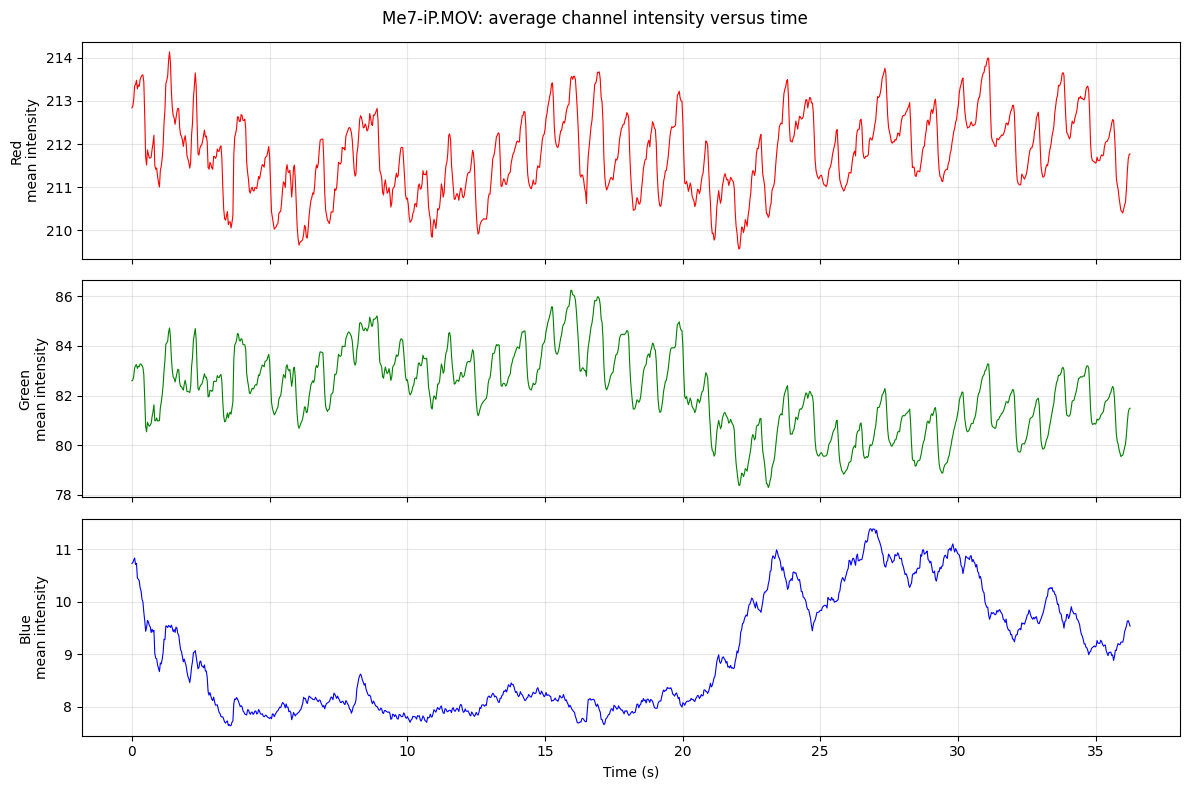

In [6]:
t1, rgb1, fs1 = average_rgb("Me7-iP.MOV")
plot_rgb(t1, rgb1, "Me7-iP.MOV: average channel intensity versus time")

### How the average channel intensity graphs are made

**What the camera is measuring.** The phone's flash shines into the fingertip, and the camera records the light that comes back out. Each heartbeat pushes a little more blood into the fingertip. Blood absorbs light, so the image gets slightly darker with each beat and slightly brighter between beats. The change is small, so we can't see it by eye, but we can measure it.

**Turning a video into three signals.** Each frame of the video is a grid of about two million pixels (1920 × 1080). Each pixel has a red, a green, and a blue value between 0 (dark) and 255 (fully bright). For every frame, the function `average_rgb` averages the red values of all the pixels, then does the same for green and for blue. That gives three numbers per frame. Doing this for every frame gives three signals: the average red, green, and blue brightness over time, with one sample per frame (about 30 samples per second).

**The time axis.** Each point is plotted at the timestamp the video file stores for that frame, rather than at frame number ÷ 30. Phone video frames are not perfectly evenly spaced: most are 33.3 ms apart, but some are 31.7 ms or 35.0 ms apart. The stored timestamps are the accurate ones.

**How to read the graphs.**
- There are three panels, one for each color, all sharing the same time axis in seconds.
- The y-axis is the average brightness of that color on the 0 to 255 scale. **Each panel has its own y-axis range**, zoomed in on that channel so that small changes are visible. Because the scales differ, don't compare the heights of the wiggles from one panel to another.
- **The fast up-and-down wiggles, about one per second, are the heartbeat.**
- **The slower wandering underneath, over several seconds, is drift.** It comes from things like the camera adjusting its exposure or the finger shifting or pressing harder. The filter in the next parts keeps the heartbeat and removes the drift.
- A steep ramp at the very start of a recording (for example, the first 3 seconds of `NotMe7-iP.MOV`) is the camera's automatic exposure settling.

**One caveat.** These videos are recorded in 10-bit HDR. OpenCV converts each frame to standard 8-bit color before we average it, and the exact conversion depends on the software version. The same video can therefore give somewhat different brightness levels on different computers. The timing of the beats is the same either way.

## Part 2: Design a filter to isolate the pulsatile frequency of interest

  Red  : drift sinks into the floor at 0.32 Hz, strongest drift 19.4 dB above the floor
  Green: drift sinks into the floor at 0.32 Hz, strongest drift 26.5 dB above the floor
  Blue : drift sinks into the floor at 0.53 Hz, strongest drift 42.1 dB above the floor
  stopband 0 to 0.53 Hz | passband 0.70 to 3.50 Hz | stopband above 3.67 Hz | attenuation 62.1 dB


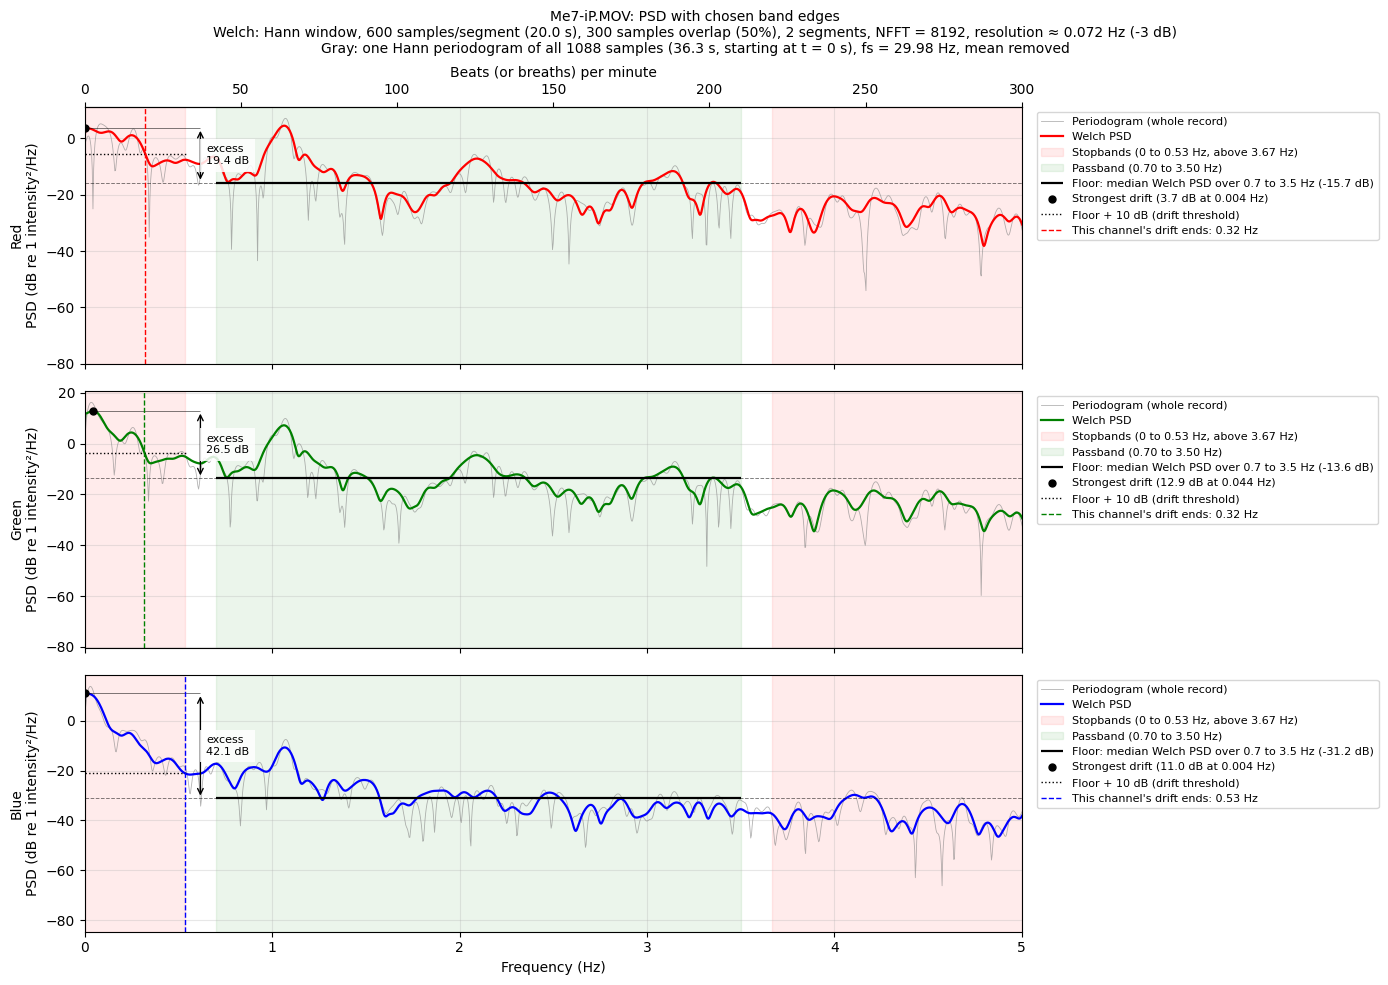

In [7]:
psd1, cut1 = psd_with_cutoffs(t1, rgb1, fs1, "Me7-iP.MOV: PSD with chosen band edges")

### Summary: how the Part 2 PSD was made

This PSD is of the **raw (unfiltered)** channel averages. Its only job is to choose the filter's band edges and attenuation. Part 8 makes a second PSD, of the **filtered** output, to estimate the heart rate.

| Step or constant | Value | How it was chosen |
|---|---|---|
| Even spacing | Linear interpolation onto a grid at the frame rate $f_s$ | The FFT assumes evenly spaced samples; the frame timestamps vary from 31.7 to 35.0 ms apart. |
| Mean | Removed (drift kept) | The mean would make a huge spike at 0 Hz; the drift is kept so its strength can be measured. |
| Start skipped | 3 s for `NotMe7-iP.MOV`, none for the others | Removes the camera's auto-exposure ramp. |
| Method and window | Welch's method, Hann window | Averaging segments reduces random variation; the Hann window keeps the cut ends of each segment from creating false frequencies. |
| Segment length | 20 s | A 20 s Hann segment smears each frequency by about ±0.1 Hz (±0.2 Hz for 10 s), which is needed to see where the drift near 0 Hz ends. |
| Overlap | 50% | The usual choice for a Hann window. |
| NFFT | 8192 | Draws a smooth curve; it does not add frequency detail. |
| Passband | 0.7 to 3.5 Hz (42 to 210 bpm) | Fixed: the range of heart rates the filter should detect. It is not moved to fit any one video. |
| Floor | Median Welch PSD over the passband | The typical level there; the median ignores the heartbeat peaks. |
| Drift threshold | Floor + 10 dB | Far enough above the floor that random wobble (only 2 segments are averaged) is not counted as drift. |
| Lower stopband edge | Where the drift drops below the threshold, kept between 0.15 and 0.55 Hz | 0.55 Hz keeps a transition of at least 0.15 Hz (limits the filter length); 0.15 Hz always removes the slowest drift. |
| Attenuation margin | Strongest drift above the floor + 20 dB | Leaves the drift at about one tenth of the floor's amplitude. |
| Channels that decide (Me7-iP) | Red and green (`decide_with=(0, 1)`) | Blue is very dim (about 9 out of 255). With blue deciding, the filter needed 691 taps and 11.5 s edge regions, leaving 13.2 s of usable data. |

### How the PSD with adjustable band edges works

**What a PSD shows.** The time plots in Part 1 show how brightness changes over time. The **power spectral density (PSD)** shows the same signal sorted by *how fast* it changes.
- The bottom x-axis is **frequency**: how many times per second something repeats, in hertz (Hz).
- The top axis shows the same frequency **per minute** (Hz × 60), so a heartbeat at 1 Hz appears at 60 beats per minute.
- The y-axis shows **how much of the signal's power** is at each frequency. A strong, regular rhythm makes a tall, narrow peak. Random noise makes a rough, spread-out floor.

**Decibels (dB).** The y-axis uses decibels, which is a logarithmic scale. Every 10 dB is a factor of 10 in power, so a peak 20 dB above its surroundings is 100 times stronger. This lets the very strong drift and the very weak noise fit on the same plot.

**Step 1: Compute the PSD (`rgb_psd`).**
1. **Optionally skip the start.** For `NotMe7-iP.MOV` we skip the first 3 seconds (`t_start=3.0`) so the auto-exposure ramp doesn't dominate the spectrum.
2. **Make the samples evenly spaced.** The PSD math (the FFT) assumes the samples are equally spaced in time. Each signal is resampled onto an evenly spaced grid at the video's frame rate by drawing straight lines between neighboring frames.
3. **Remove the average.** We subtract each channel's mean brightness. Otherwise the steady brightness level would create a huge spike at 0 Hz that hides everything else. The slow drift is deliberately left in, because we want to see how strong it is.
4. **Welch's method (the colored line).** The signal is cut into 20-second pieces that overlap by half. Each piece is tapered with a **Hann window**, which fades it in and out so the cut ends don't create false frequencies. The spectrum of each piece is computed, and the spectra are averaged. Averaging smooths out random ups and downs.
5. **Periodogram (the gray line).** This is a single spectrum of the whole recording, computed in one go. It shows finer detail but is much noisier: individual spikes and dips of 10 to 20 dB can be pure chance. **Only trust a feature that shows up in both lines.**

**The subtitle** lists the exact settings:
- the number of samples per piece (and seconds), the overlap, and the number of pieces averaged;
- **NFFT**, the number of frequency points computed. More points make the curve smoother to look at, but they do not add real detail.
- the **resolution**: two peaks closer together than this blur into one.

**Why 20-second pieces?** It's a tradeoff. Longer pieces show finer detail but leave fewer pieces to average, so the result is noisier. A 20-second Hann window smears each frequency over about ±0.1 Hz. With 10-second pieces, the smear would be about ±0.2 Hz, which would make the drift appear to reach higher frequencies than it really does. For a 36-second video, 20-second pieces leave only 2 pieces to average.

**Step 2: Choose the band edges (`choose_cutoffs`).** The filter in the next parts needs three kinds of regions:
- a **passband**, the frequencies to keep;
- **stopbands**, the frequencies to remove;
- **transition bands**, the gaps between them where the filter changes from keeping to removing.

The edges are chosen like this:
1. **The passband is fixed at 0.7 to 3.5 Hz (42 to 210 beats per minute).** This is the range of heart rates we want to be able to detect. It stays fixed on purpose: if we moved it to wherever this video's peak happens to be, the filter would be assuming the answer before we measure it.
2. **Floor.** For each channel, the floor is the median PSD across the passband, which is the typical level there. The median is used instead of the average so the heartbeat peaks don't pull it up.
3. **Threshold.** The threshold is the floor + 10 dB, ten times the floor's power. It is drawn as a **dotted black line**.
4. **Lower stopband edge.** Between 0 and 0.55 Hz, the code finds the highest frequency where the PSD is still above the threshold. That is where the drift sinks into the floor, and it is marked with a **dashed line in the channel's color**.
   - If nothing rises above the threshold, the minimum of 0.15 Hz is used, and the label says so.
   - The 0.55 Hz upper limit keeps at least 0.15 Hz of transition below the 0.7 Hz passband edge, which limits how long the filter can get.
   - The 0.15 Hz lower limit makes sure the filter always removes at least the slowest drift.
5. **The worst channel decides.** One filter is used for all three channels, so the channel whose drift reaches highest sets the edge. A channel left out with `decide_with` is still plotted, but it doesn't help set the edge, and the printout marks it "not used to decide."
6. **Upper stopband edge.** This is 3.5 Hz plus the same transition width as on the low side, so both edges of the filter are equally sharp.
7. **Attenuation.** This is how much the filter must weaken the stopbands. The code measures how far the strongest drift sits above the floor and adds a 20 dB margin. After filtering, the drift should sit at least 20 dB (100 times) below the typical level in the passband.

**How to read the plot.**
- **Red shading** marks the stopbands, **green shading** marks the passband, and the white gaps between them are the transition bands.
- **The tall peak inside the green band is the heart rate.** In `Me7-iP.MOV` and `IMG_1133.MOV`, it is near 1.07 Hz (about 64 beats per minute).
- **Smaller peaks at 2 and 3 times that frequency are harmonics.** They appear because the pulse is not a pure sine wave: it rises quickly and falls slowly.
- **The rise at the far left is the drift** that the lower stopband removes.
- **If no peak stands out from the rest** (as in `NotMe7-iP.MOV`), there is no clear pulse in that recording.
- The printout under each plot lists each channel's drift edge, how far its drift sits above the floor, and the final band edges and attenuation.

**Design choices (not measured).** These values were chosen, not taken from the data:
- the 10 dB threshold
- the 20 dB margin
- the 0.15 to 0.55 Hz search range
- the 0.7 to 3.5 Hz passband

A different threshold would move the edges. The PSD measures *where* the drift ends for each video once these rules are set.

In [8]:
filt1 = design_kaiser(cut1, fs1)
design_table([("Me7-iP.MOV", cut1, filt1)])


#### Design decisions (the same for every video)

| # | Decision | Choice | Why |
|---|---|---|---|
| 1 | IIR or FIR? | **FIR** | A FIR filter's impulse response has exactly $N$ taps, so the edge effects last exactly $M = (N-1)/2$ samples at each end (Part 4). Its impulse response is finite and symmetric, so it can be plotted exactly (Part 3). Its phase is linear, and zero when applied centered (Part 6). It is always stable. The recordings are processed offline, so the longer length of a FIR filter costs nothing that matters. An IIR Butterworth filter run forwards and backwards (`sosfiltfilt`) was considered: it is also zero-phase and slightly shorter, but its magnitude is squared and its edge effects only fade away gradually, so Parts 4 to 6 would rest on estimates instead of exact values. |
| 2 | FIR design method? | **Kaiser window** | The Kaiser window's shape parameter $\beta$ sets the stopband attenuation, so each video gets exactly the attenuation it needs. `kaiserord` gives the length $N$ and $\beta$ directly from two numbers we already have: the required attenuation and the transition width. On three test specifications, the fixed windows (Hann, Hamming, Blackman) needed about 15% to 70% more taps than Kaiser to meet the same requirements. Parks-McClellan (equiripple) needed 3% to 10% fewer taps, but it has no formula for the length (it needs a search), it failed to converge in two of three tests when the upper transition was widened, and it is harder to explain. |
| 3 | Filter type? | **Bandpass** | The PSD shows slow drift below about 0.3 Hz that is as strong as the pulse or stronger, so a lower stopband is needed (highpass side). Above the pulse harmonics the PSD is broadband noise, so an upper stopband removes the noise outside the band of interest (lowpass side). |
| 4 | How is it applied? | **Centered (non-causal), zero phase** | Each output sample $y[n]$ uses the inputs $x[n-M]$ to $x[n+M]$. The pulse is not delayed or distorted. This is possible because the whole recording is available before filtering. The causal version would delay everything by $M$ samples. |
| 5 | Length odd or even? | **Odd** | An odd length has a center tap, so the filter can be centered exactly on each sample. |
| 6 | Where are the cutoffs? | **Middle of each transition band** | A windowed-sinc filter's gain is about 0.5 (−6 dB) halfway through each transition band, so the −6 dB cutoff frequencies are the midpoints. |

#### Filter for each video

| Band or value | How it is chosen | Me7-iP.MOV |
|---|---|---|
| Channels that set the edges | One filter is used for all three channels, so the worst of these channels decides | Red, Green, Blue |
| **Lower stopband** | From 0 Hz up to where the drift sinks below the floor + 10 dB (the floor is the median Welch PSD over the passband) | 0 to 0.53 Hz (32 bpm) |
| **Transition band 1** | From the lower stopband edge to the lower passband edge | 0.53 to 0.70 Hz (width 0.17 Hz) |
| Lower cutoff (−6 dB) | Midpoint of transition band 1 | 0.62 Hz (37 bpm) |
| **Passband** | Fixed: the range of heart rates the filter is meant to detect | 0.70 Hz (42 bpm) to 3.50 Hz (210 bpm) |
| **Transition band 2** | Same width as transition band 1 (the Kaiser window method uses one transition width) | 3.50 to 3.67 Hz (width 0.17 Hz) |
| Upper cutoff (−6 dB) | Midpoint of transition band 2 | 3.58 Hz (215 bpm) |
| **Upper stopband** | From the upper stopband edge to half the frame rate ($f_s/2$) | 3.67 to 14.99 Hz |
| Required stopband attenuation | Strongest drift above the floor + 20 dB margin | 62.1 dB |
| Achieved stopband attenuation | Measured from the designed filter's frequency response | 62.4 dB |
| Passband gain | Measured: lowest to highest gain between the passband edges | -0.005 to +0.007 dB |
| Kaiser β | From `kaiserord`: larger β gives more stopband attenuation (and needs more taps for the same transition width) | 5.941 |
| Length N | From `kaiserord`, made odd: longer for more attenuation or a narrower transition | 691 taps (23.05 s) |
| Edge region at each end | Half-length M = (N − 1)/2 samples (Part 4) | 345 samples (11.51 s) |
| Sampling rate $f_s$ | Frame rate of the video | 29.98 Hz |

### Without the blue channel:

  Red  : drift sinks into the floor at 0.32 Hz, strongest drift 19.4 dB above the floor
  Green: drift sinks into the floor at 0.32 Hz, strongest drift 26.5 dB above the floor
  Blue : drift sinks into the floor at 0.53 Hz, strongest drift 42.1 dB above the floor   (not used to decide)
  stopband 0 to 0.32 Hz | passband 0.70 to 3.50 Hz | stopband above 3.88 Hz | attenuation 46.5 dB


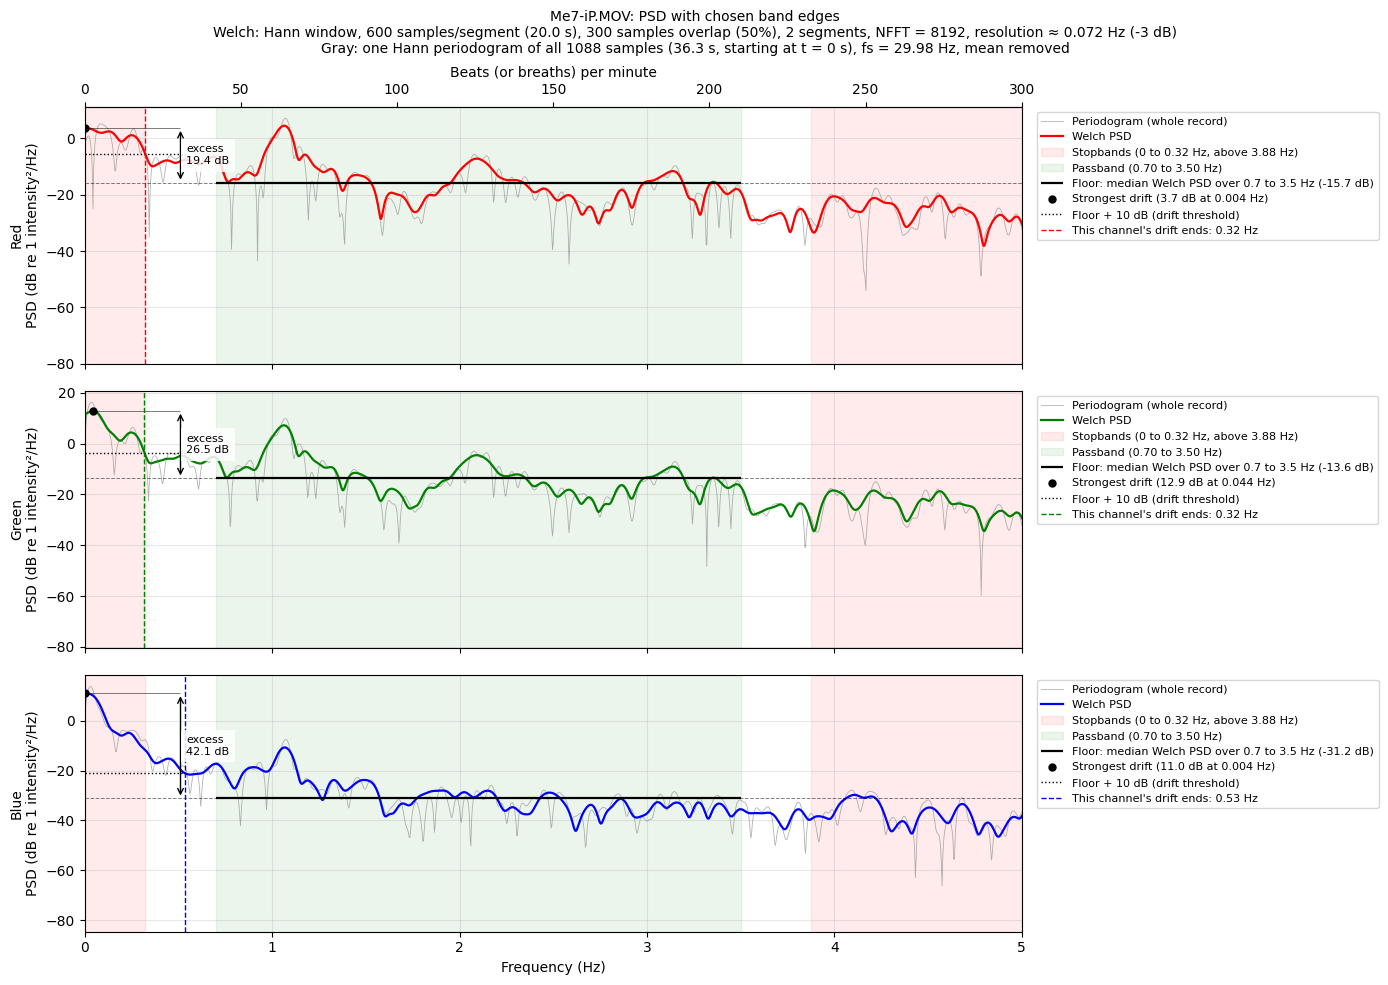

In [9]:
psd1, cut1 = psd_with_cutoffs(t1, rgb1, fs1, "Me7-iP.MOV: PSD with chosen band edges", decide_with=(0, 1))

In [10]:
filt1 = design_kaiser(cut1, fs1)
design_table([("Me7-iP.MOV", cut1, filt1)], show_common=False)

#### Filter for each video

| Band or value | How it is chosen | Me7-iP.MOV |
|---|---|---|
| Channels that set the edges | One filter is used for all three channels, so the worst of these channels decides | Red, Green |
| **Lower stopband** | From 0 Hz up to where the drift sinks below the floor + 10 dB (the floor is the median Welch PSD over the passband) | 0 to 0.32 Hz (19 bpm) |
| **Transition band 1** | From the lower stopband edge to the lower passband edge | 0.32 to 0.70 Hz (width 0.38 Hz) |
| Lower cutoff (−6 dB) | Midpoint of transition band 1 | 0.51 Hz (31 bpm) |
| **Passband** | Fixed: the range of heart rates the filter is meant to detect | 0.70 Hz (42 bpm) to 3.50 Hz (210 bpm) |
| **Transition band 2** | Same width as transition band 1 (the Kaiser window method uses one transition width) | 3.50 to 3.88 Hz (width 0.38 Hz) |
| Upper cutoff (−6 dB) | Midpoint of transition band 2 | 3.69 Hz (221 bpm) |
| **Upper stopband** | From the upper stopband edge to half the frame rate ($f_s/2$) | 3.88 to 14.99 Hz |
| Required stopband attenuation | Strongest drift above the floor + 20 dB margin | 46.5 dB |
| Achieved stopband attenuation | Measured from the designed filter's frequency response | 48.0 dB |
| Passband gain | Measured: lowest to highest gain between the passband edges | -0.021 to +0.039 dB |
| Kaiser β | From `kaiserord`: larger β gives more stopband attenuation (and needs more taps for the same transition width) | 4.373 |
| Length N | From `kaiserord`, made odd: longer for more attenuation or a narrower transition | 227 taps (7.57 s) |
| Edge region at each end | Half-length M = (N − 1)/2 samples (Part 4) | 113 samples (3.77 s) |
| Sampling rate $f_s$ | Frame rate of the video | 29.98 Hz |

## Part 3: Plot the impulse response of your filter

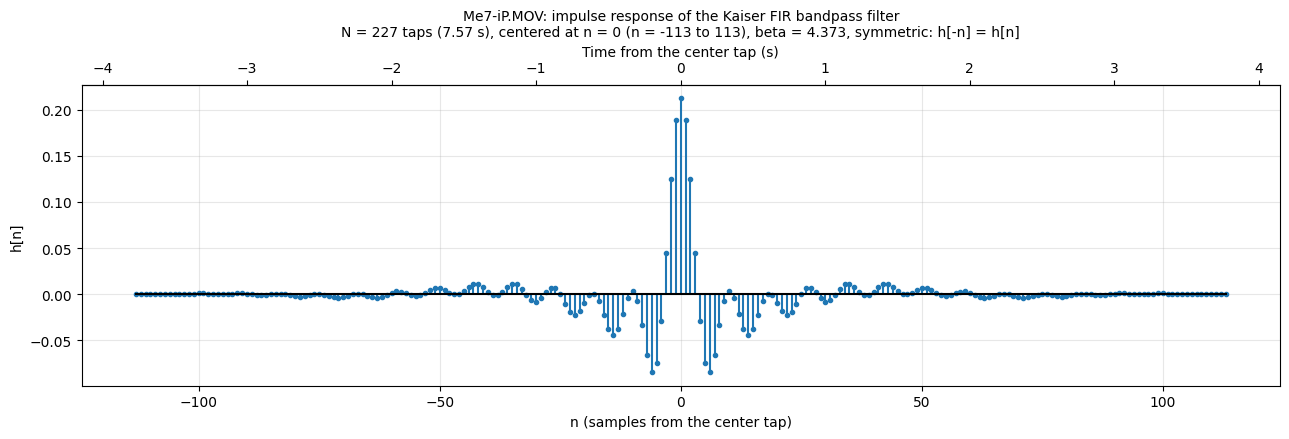

In [11]:
plot_impulse(filt1, "Me7-iP.MOV")

## Part 4: How long do you estimate it would take for the edge effects to become negligible for your filter?

Me7-iP.MOV
  Exact: the edge regions are the first and last M = 113 samples = 3.77 s.
  Worst case (a): less than 1% of sum|h| is missing once the output is 2.43 s from an end.
  Measured (b), Red  : within 1% of the steady-state RMS from 3.10 s to 33.72 s (3.10 s from the start, 2.57 s from the end)
  Measured (b), Green: within 1% of the steady-state RMS from 2.87 s to 33.75 s (2.87 s from the start, 2.53 s from the end)
  Measured (b), Blue : within 1% of the steady-state RMS from 3.60 s to 32.88 s (3.60 s from the start, 3.40 s from the end)


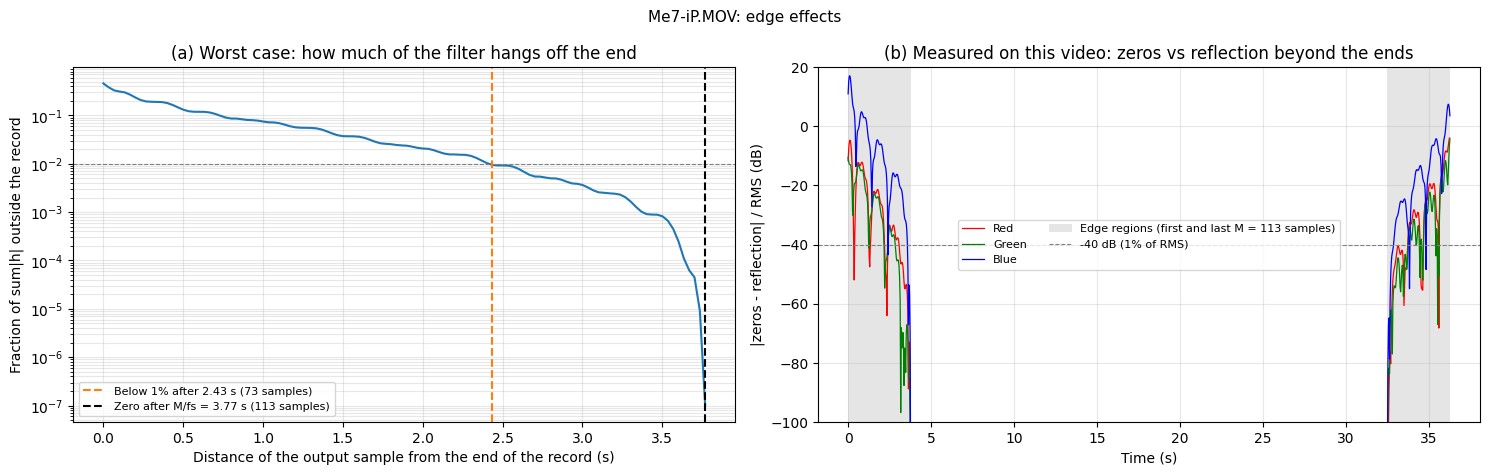

In [12]:
edge_effects(filt1, t1, rgb1, "Me7-iP.MOV")

## Part 5: Plot the magnitude response of your filter

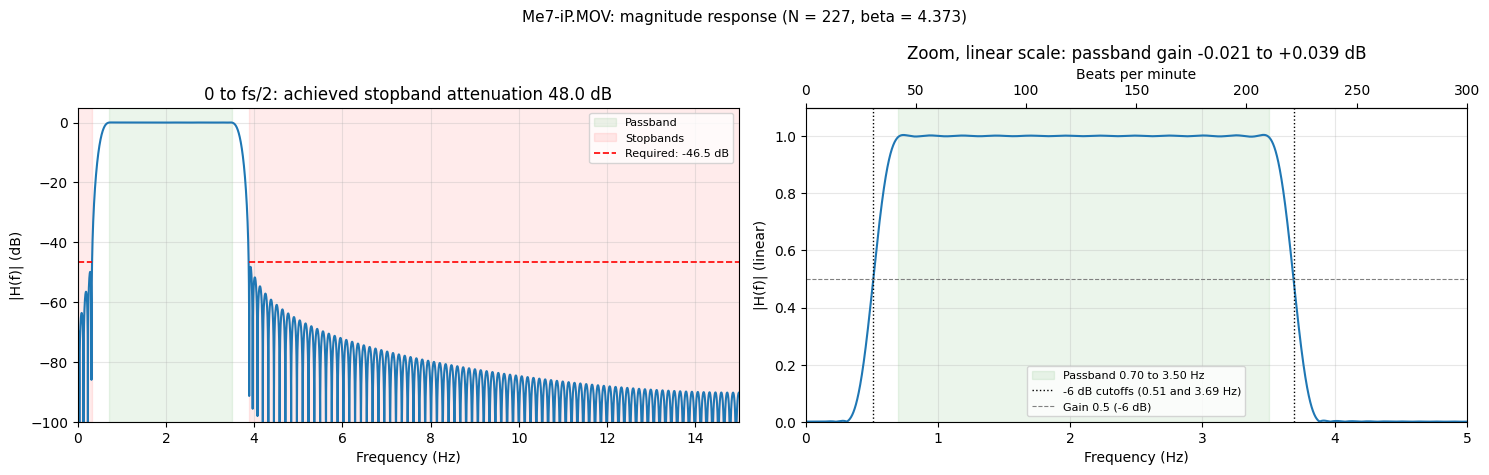

In [13]:
plot_magnitude(filt1, "Me7-iP.MOV")

## Part 6: Plot the phase response of your filter

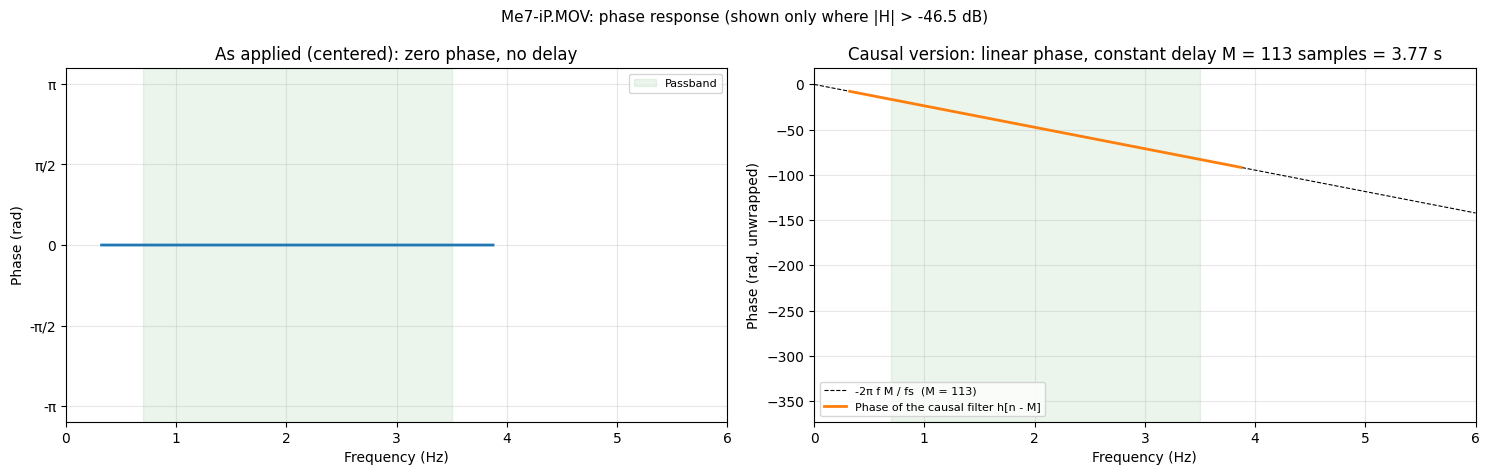

In [14]:
plot_phase(filt1, "Me7-iP.MOV")

## Part 7: Plot the output of your filter for each of the color channels

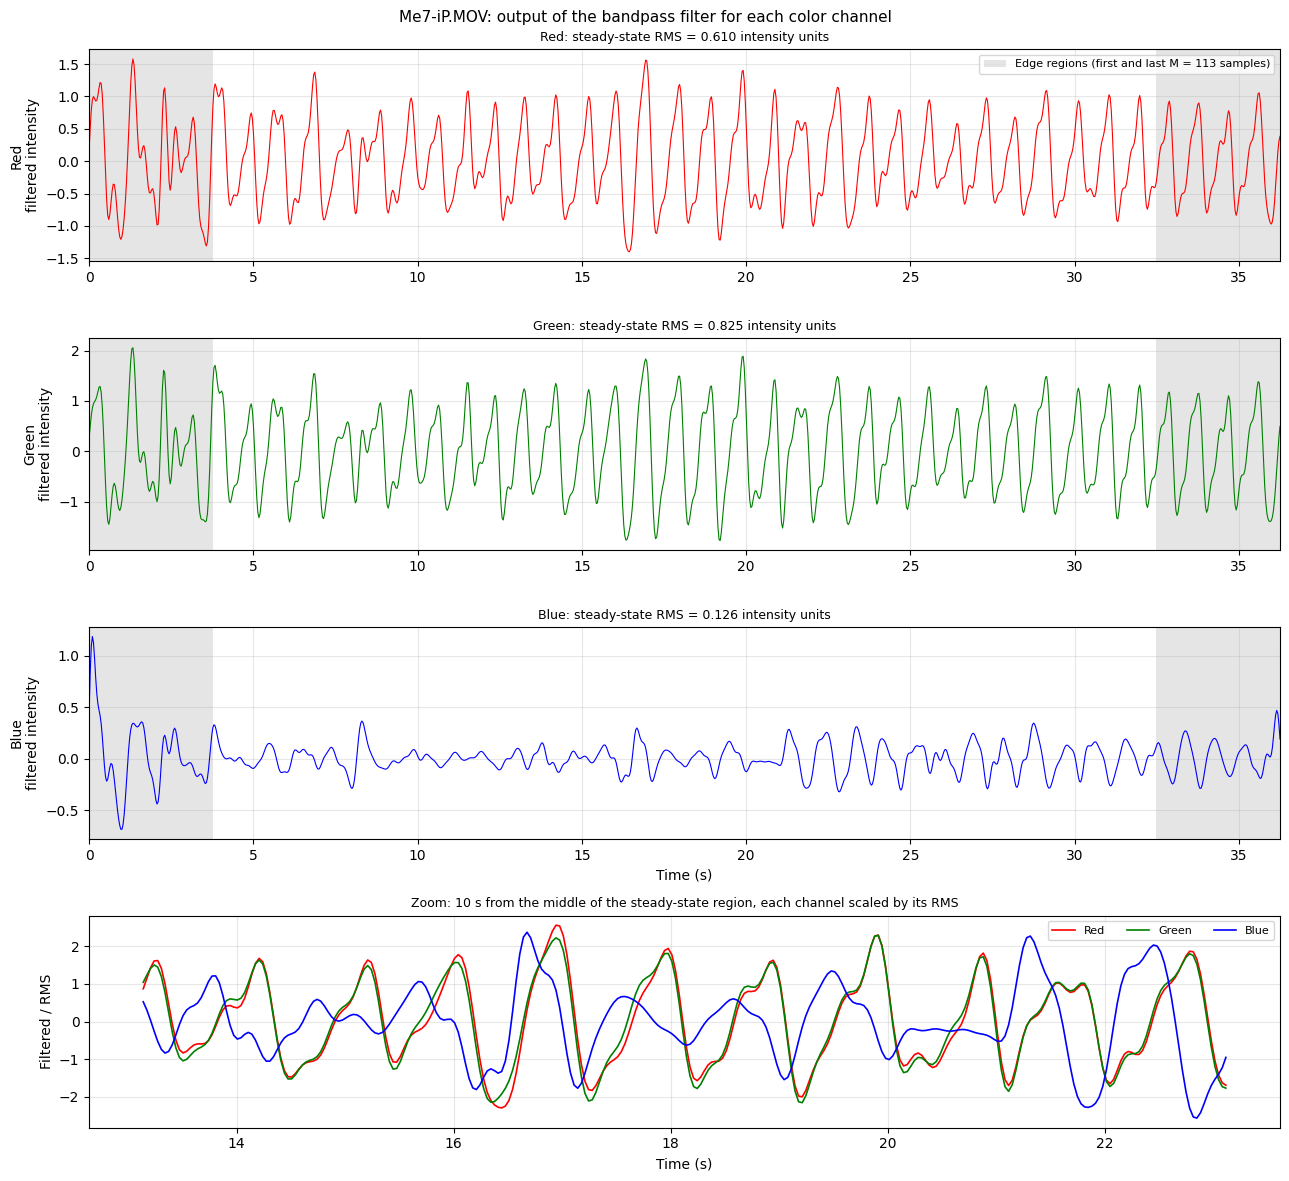

Me7-iP.MOV: steady state 3.77 s to 32.48 s (28.7 s of the 36.3 s record)
  correlation between channels: R-G +0.99, R-B -0.15, G-B -0.09


In [15]:
y1 = filter_rgb(filt1, t1, rgb1)
plot_filtered(y1, "Me7-iP.MOV")

## Part 8: Determine an approach to estimating the power spectral density

### PSD design decisions (heart-rate PSD)

| Decision | Choice | Why |
|---|---|---|
| Data | The **filtered** output, **steady-state samples only** | Samples within $M$ of either end depend on what is assumed beyond the record (Part 4). The filter has already removed the drift. |
| Method | **Welch's method** (averaged, windowed periodograms) | A single periodogram does not get less noisy with a longer record: at each frequency its standard deviation equals its mean. Averaging $K$ segments reduces that. |
| Window | **Hann** | Its sidelobes start at −31 dB and fall 18 dB per octave, so the strong fundamental does not leak over its harmonics. |
| Segment length | **10 s** (about 300 samples) | Holds at least 7 beats even at 42 bpm. The −3 dB resolution is about 0.14 Hz (8.6 bpm). The heart rate itself wanders by a few bpm during a recording (see the 10-s estimates in Part 10), so finer resolution gains little, and shorter segments give more segments to average. This is shorter than Part 2's 20 s because the drift near 0 Hz is already filtered out. |
| Overlap | **50%** | The usual choice for a Hann window; it recovers most of the averaging of fully independent segments. |
| FFT length | **8192** (zero-padded) | Samples the PSD every 0.0037 Hz (0.22 bpm), so the peak's location is not rounded to the 0.1 Hz (6 bpm) spacing of a 300-point FFT. Zero padding does not improve resolution. |
| Scaling | One-sided density (intensity²/Hz) | The area under the PSD equals the power of the filtered signal. |
| Comparison | Gray: one Hann periodogram of the whole steady-state record | Finer detail but much noisier; trust only features that appear in both. |

The printout below gives this video's number of samples and segments.

In [16]:
pz1 = hr_psd(y1, filt1)

Welch PSD of the filtered steady-state output: 862 samples (28.7 s, from t = 3.77 s), Hann window, 300 samples/segment (10.0 s), 150 samples overlap (50%), 4 segments
  NFFT = 8192 (PSD every 0.0037 Hz = 0.22 bpm), resolution ≈ 0.144 Hz = 8.6 bpm (-3 dB), one-sided density


## Part 9: Plot the Power Spectral Density for each of the color channels

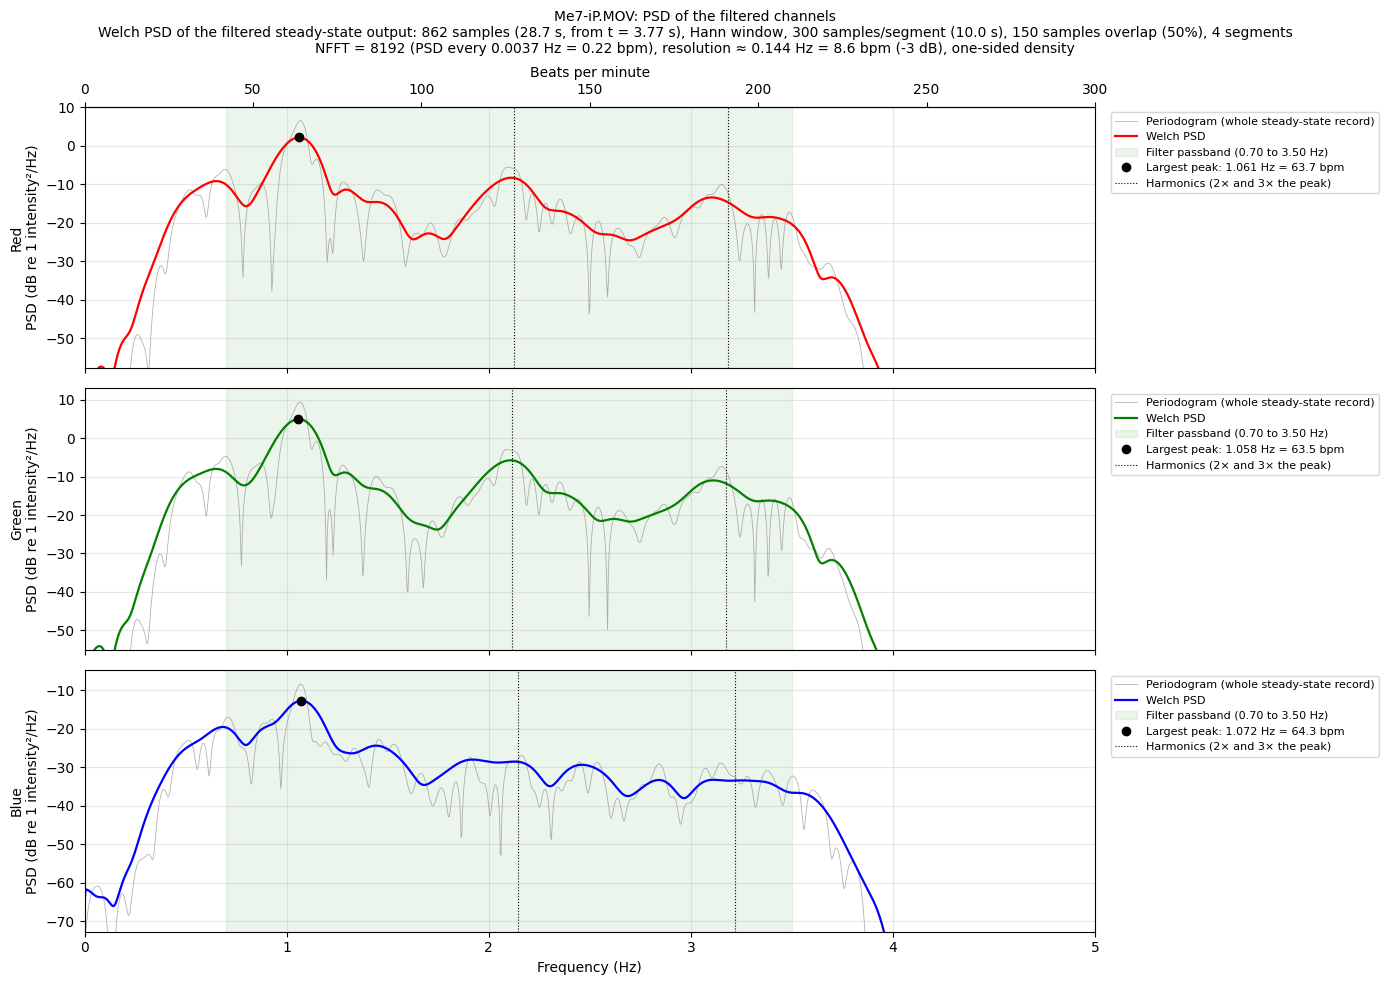

In [17]:
plot_hr_psd(pz1, "Me7-iP.MOV")

## Part 10: Estimate the pulse (heart) rate, if present

### How the heart rate is estimated

1. **Peak.** The largest Welch PSD peak in the passband (0.7 to 3.5 Hz).
2. **Harmonic check.** If the PSD at half that frequency is at least half as tall, the lower frequency is taken, so the 2nd harmonic is not reported as the heart rate.
3. **Presence test.** Every spectrum has a largest peak, even pure noise, so a channel counts as having a pulse only if:
   - **Peak fraction ≥ 0.5:** the peak (± one Hann main-lobe half-width, 0.2 Hz) holds at least half of the passband power. A flat noise spectrum gives about 0.14.
   - **Stability:** the same estimate on 10-s windows, moved 1 s at a time, has an interquartile range ≤ 10 bpm. A resting heart rate changes slowly; the largest noise peak jumps around.
4. A pulse is present if at least one channel passes both tests. The reported rate comes from the passing channel with the largest peak fraction.

The thresholds (0.5 and 10 bpm) are design choices. `NotMe7-iP.MOV` serves as the check that they reject a recording without a clear pulse.

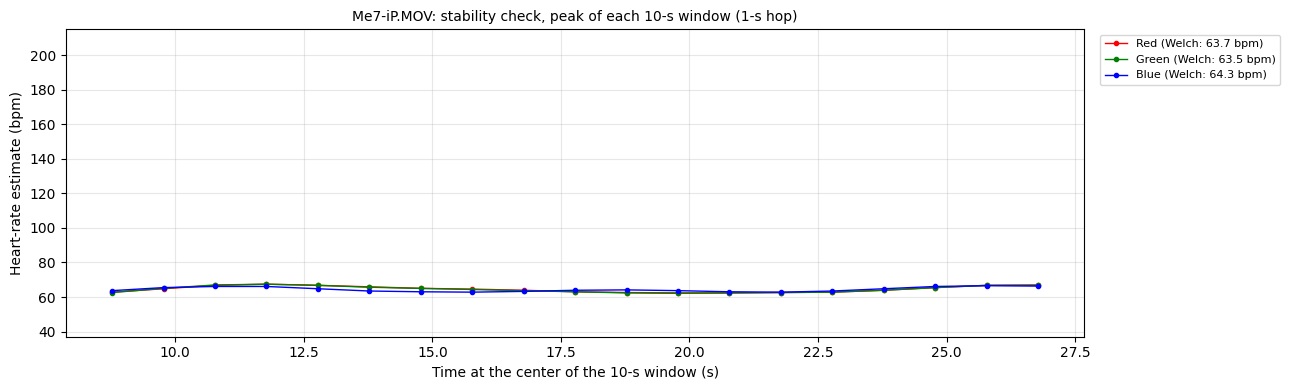

#### Me7-iP.MOV: heart-rate estimate

| Channel | Welch peak (bpm) | Peak fraction (need ≥ 0.5; noise ≈ 0.14) | 10-s median (bpm) | 10-s IQR (need ≤ 10 bpm) | Pulse? |
|---|---|---|---|---|---|
| Red | 63.7 | 0.79 | 64.6 | 3.5 | yes |
| Green | 63.5 | 0.81 | 64.3 | 3.5 | yes |
| Blue | 64.3 | 0.75 | 63.9 | 2.4 | yes |

**Pulse present. Estimated heart rate: 63.5 bpm (1.058 Hz)**, from the green channel (largest peak fraction among the channels that passed).

In [18]:
hr1 = estimate_pulse(y1, pz1, "Me7-iP.MOV")

## Part 11: Which color channels were most helpful for estimating the pulse rate?

### How to read the channel comparison

- **Mean intensity:** how much light reached the camera in that color (0 to 255). A very dim channel is noisy.
- **Pulse RMS:** the size of the filtered (pulsatile) signal, in intensity units.
- **Pulse / mean:** the pulse as a percentage of the channel's brightness, i.e. how strongly blood changes that color.
- **Peak fraction** and **10-s IQR:** the two presence tests from Part 10 (spectral purity and stability).
- **Correlation:** how closely the channel's filtered waveform follows the top-ranked channel's waveform. A channel can pass the tests but still have a waveform that does not match.
- **Ranking:** channels that passed come first, then by peak fraction, then by IQR.

In [19]:
channel_report(hr1, y1, rgb1, "Me7-iP.MOV")

#### Me7-iP.MOV: how useful each channel was

| Rank | Channel | Mean intensity | Pulse RMS | Pulse / mean | Peak fraction | 10-s IQR (bpm) | Correlation with green | Passed? |
|---|---|---|---|---|---|---|---|---|
| 1 | Green | 82.1 | 0.825 | 1.00% | 0.81 | 3.5 | +1.00 | yes |
| 2 | Red | 211.8 | 0.610 | 0.29% | 0.79 | 3.5 | +0.99 | yes |
| 3 | Blue | 9.0 | 0.126 | 1.40% | 0.75 | 2.4 | -0.09 | yes |

# Video 2: `NotMe7-iP.MOV`

## Part 1: Plot the average intensity of the red, blue, and green channels versus time

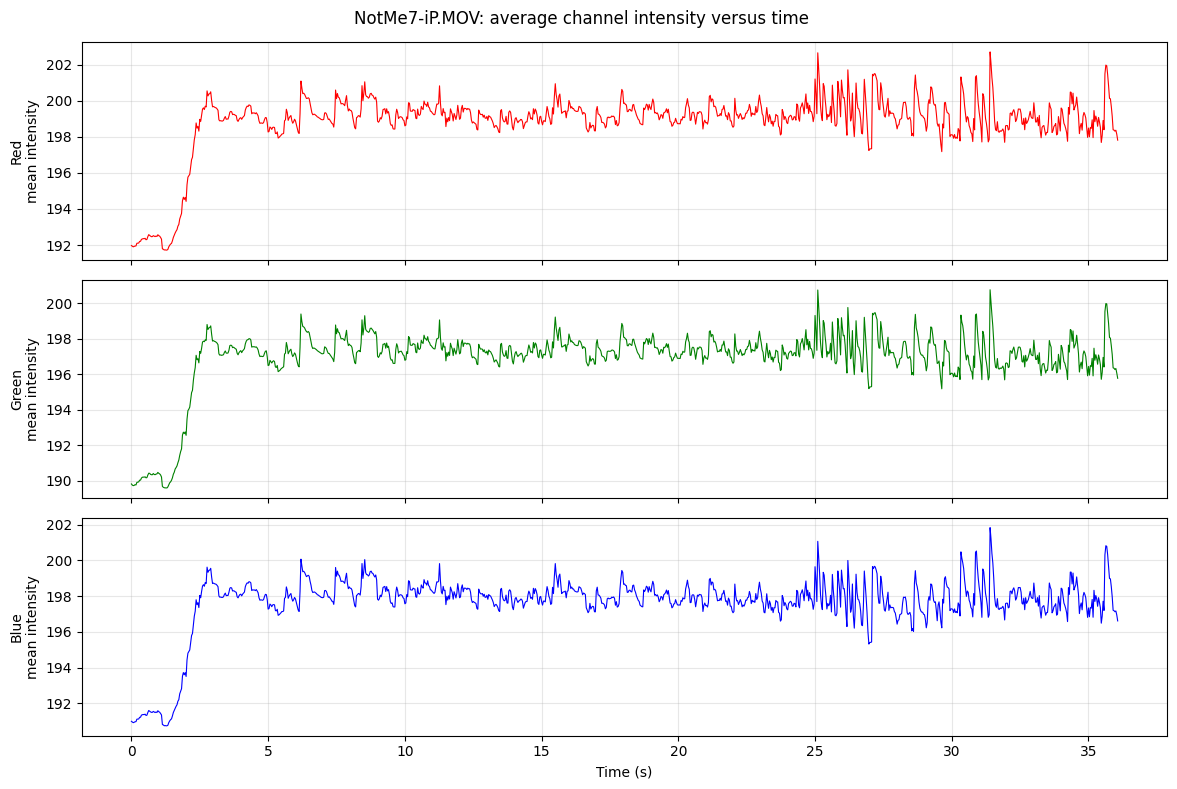

In [20]:
t2, rgb2, fs2 = average_rgb("NotMe7-iP.MOV")
plot_rgb(t2, rgb2, "NotMe7-iP.MOV: average channel intensity versus time")

## Part 2: Design a filter to isolate the pulsatile frequency of interest

  Red  : no drift above the threshold (minimum 0.15 Hz used), strongest drift 8.6 dB above the floor
  Green: no drift above the threshold (minimum 0.15 Hz used), strongest drift 8.2 dB above the floor
  Blue : drift sinks into the floor at 0.03 Hz, strongest drift 10.5 dB above the floor
  stopband 0 to 0.15 Hz | passband 0.70 to 3.50 Hz | stopband above 4.05 Hz | attenuation 30.5 dB


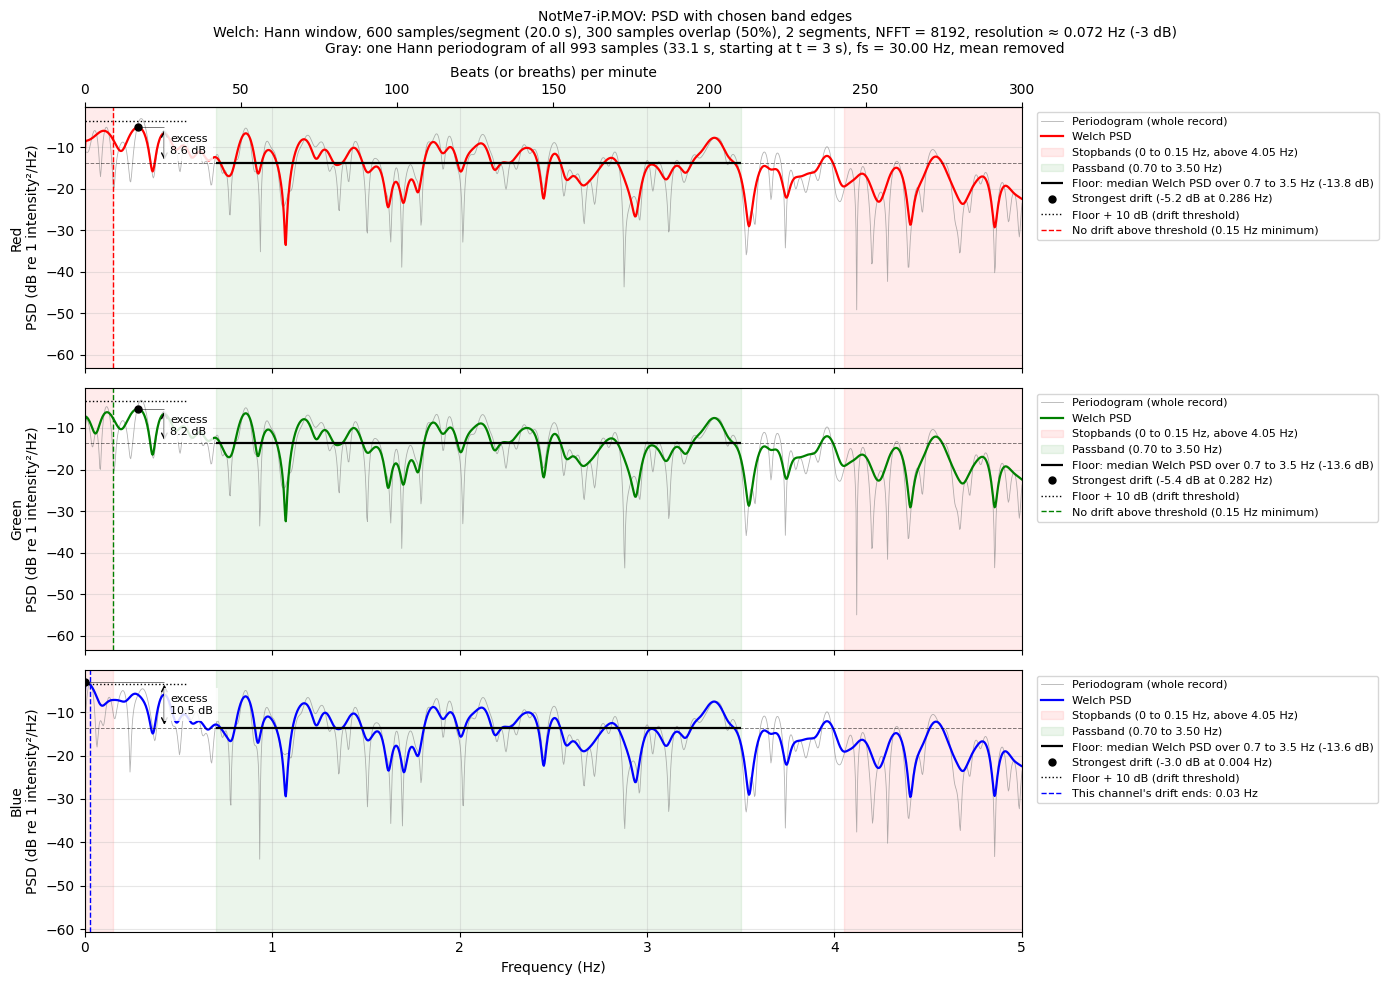

In [21]:
psd2, cut2 = psd_with_cutoffs(t2, rgb2, fs2, "NotMe7-iP.MOV: PSD with chosen band edges", t_start=3.0)

In [22]:
filt2 = design_kaiser(cut2, fs2)
design_table([("NotMe7-iP.MOV", cut2, filt2)], show_common=False)

#### Filter for each video

| Band or value | How it is chosen | NotMe7-iP.MOV |
|---|---|---|
| Channels that set the edges | One filter is used for all three channels, so the worst of these channels decides | Red, Green, Blue |
| **Lower stopband** | From 0 Hz up to where the drift sinks below the floor + 10 dB (the floor is the median Welch PSD over the passband) | 0 to 0.15 Hz (9 bpm) |
| **Transition band 1** | From the lower stopband edge to the lower passband edge | 0.15 to 0.70 Hz (width 0.55 Hz) |
| Lower cutoff (−6 dB) | Midpoint of transition band 1 | 0.42 Hz (26 bpm) |
| **Passband** | Fixed: the range of heart rates the filter is meant to detect | 0.70 Hz (42 bpm) to 3.50 Hz (210 bpm) |
| **Transition band 2** | Same width as transition band 1 (the Kaiser window method uses one transition width) | 3.50 to 4.05 Hz (width 0.55 Hz) |
| Upper cutoff (−6 dB) | Midpoint of transition band 2 | 3.77 Hz (226 bpm) |
| **Upper stopband** | From the upper stopband edge to half the frame rate ($f_s/2$) | 4.05 to 15.00 Hz |
| Required stopband attenuation | Strongest drift above the floor + 20 dB margin | 30.5 dB |
| Achieved stopband attenuation | Measured from the designed filter's frequency response | 31.1 dB |
| Passband gain | Measured: lowest to highest gain between the passband edges | -0.082 to +0.231 dB |
| Kaiser β | From `kaiserord`: larger β gives more stopband attenuation (and needs more taps for the same transition width) | 2.725 |
| Length N | From `kaiserord`, made odd: longer for more attenuation or a narrower transition | 103 taps (3.43 s) |
| Edge region at each end | Half-length M = (N − 1)/2 samples (Part 4) | 51 samples (1.70 s) |
| Sampling rate $f_s$ | Frame rate of the video | 30.00 Hz |

## Part 3: Plot the impulse response of your filter

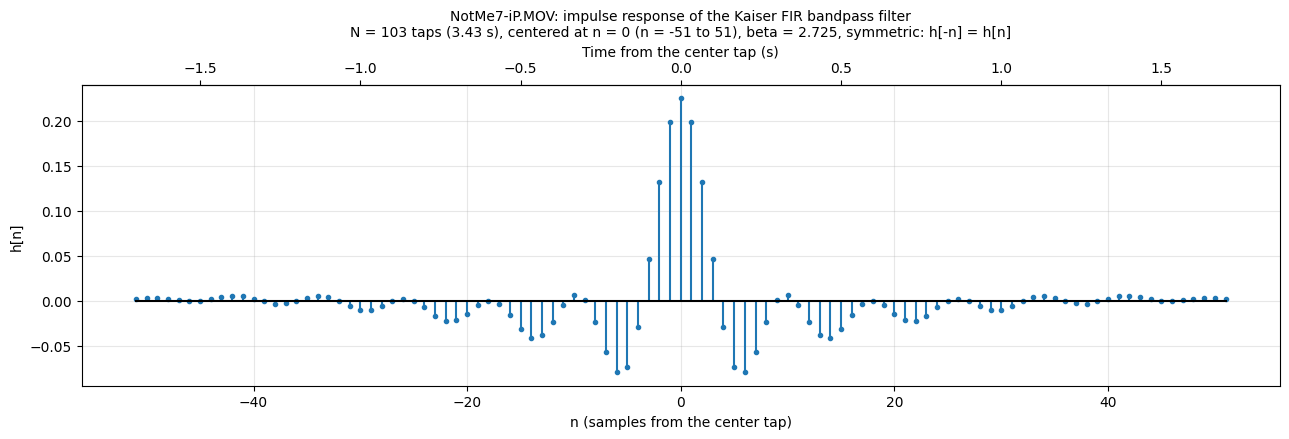

In [23]:
plot_impulse(filt2, "NotMe7-iP.MOV")

## Part 4: How long do you estimate it would take for the edge effects to become negligible for your filter?

NotMe7-iP.MOV
  Exact: the edge regions are the first and last M = 51 samples = 1.70 s.
  Worst case (a): less than 1% of sum|h| is missing once the output is 1.40 s from an end.
  Measured (b), Red  : within 1% of the steady-state RMS from 1.60 s to 31.44 s (1.60 s from the start, 1.67 s from the end)
  Measured (b), Green: within 1% of the steady-state RMS from 1.63 s to 31.44 s (1.63 s from the start, 1.67 s from the end)
  Measured (b), Blue : within 1% of the steady-state RMS from 1.63 s to 31.44 s (1.63 s from the start, 1.67 s from the end)


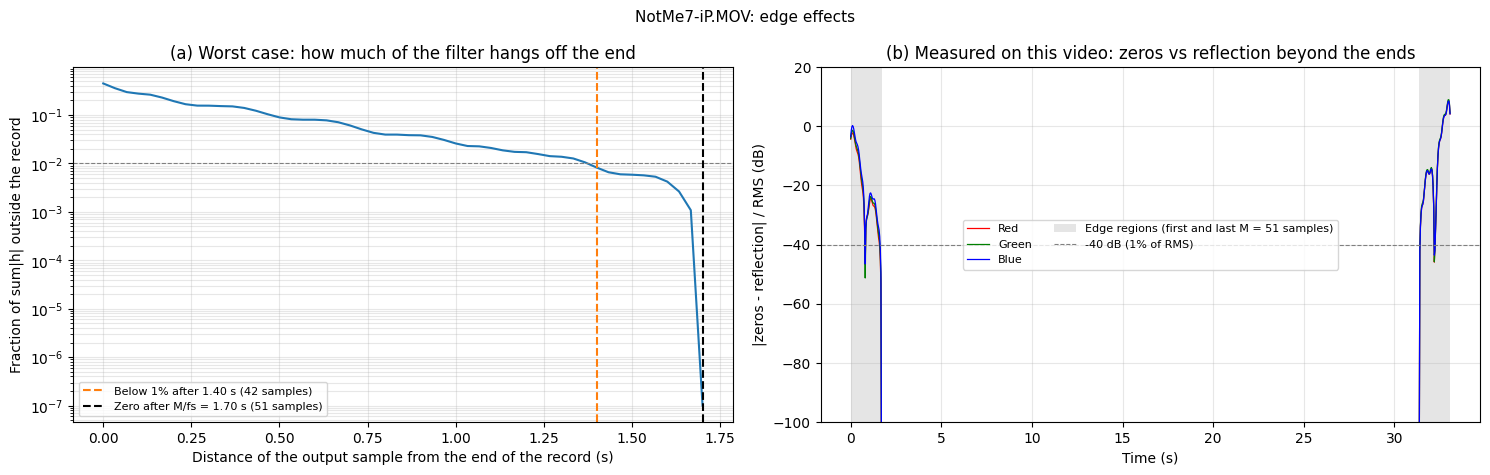

In [24]:
edge_effects(filt2, t2, rgb2, "NotMe7-iP.MOV", t_start=3.0)

## Part 5: Plot the magnitude response of your filter

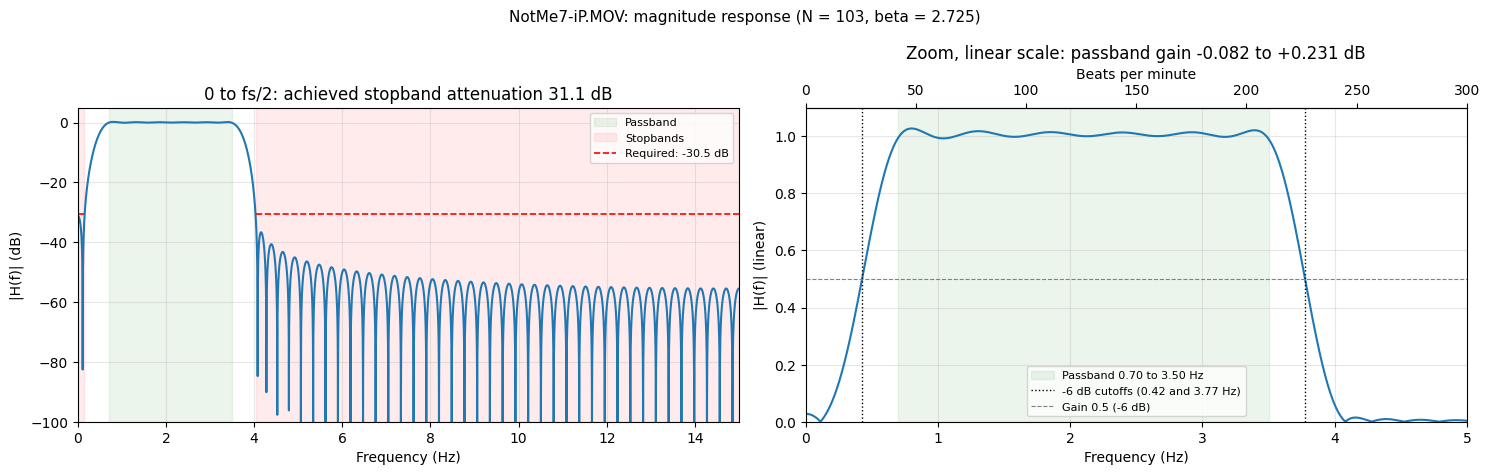

In [25]:
plot_magnitude(filt2, "NotMe7-iP.MOV")

## Part 6: Plot the phase response of your filter

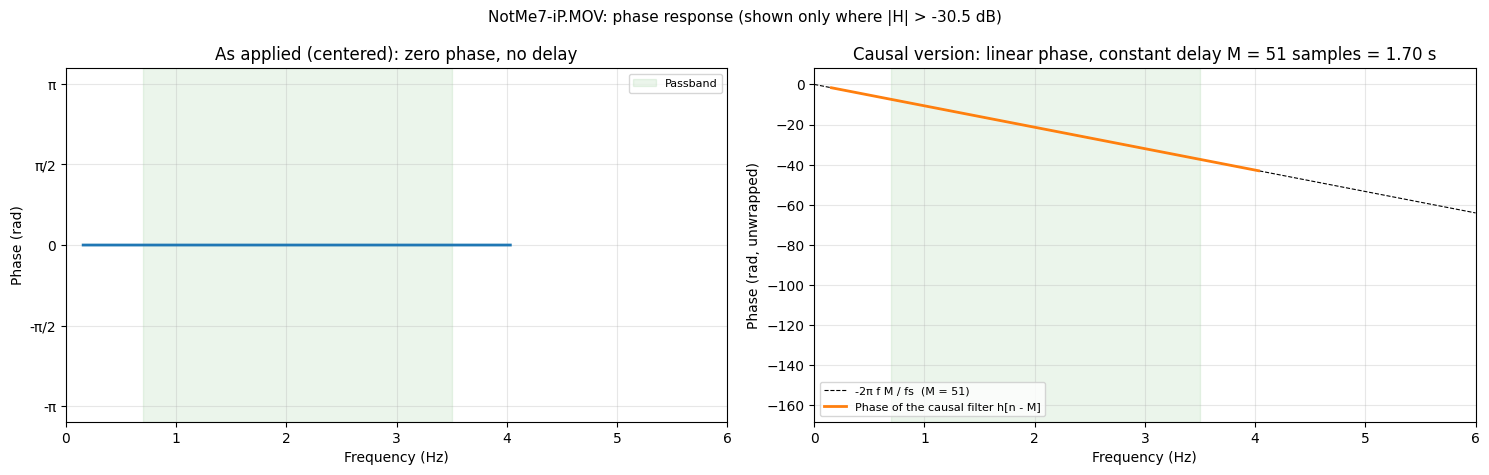

In [26]:
plot_phase(filt2, "NotMe7-iP.MOV")

## Part 7: Plot the output of your filter for each of the color channels

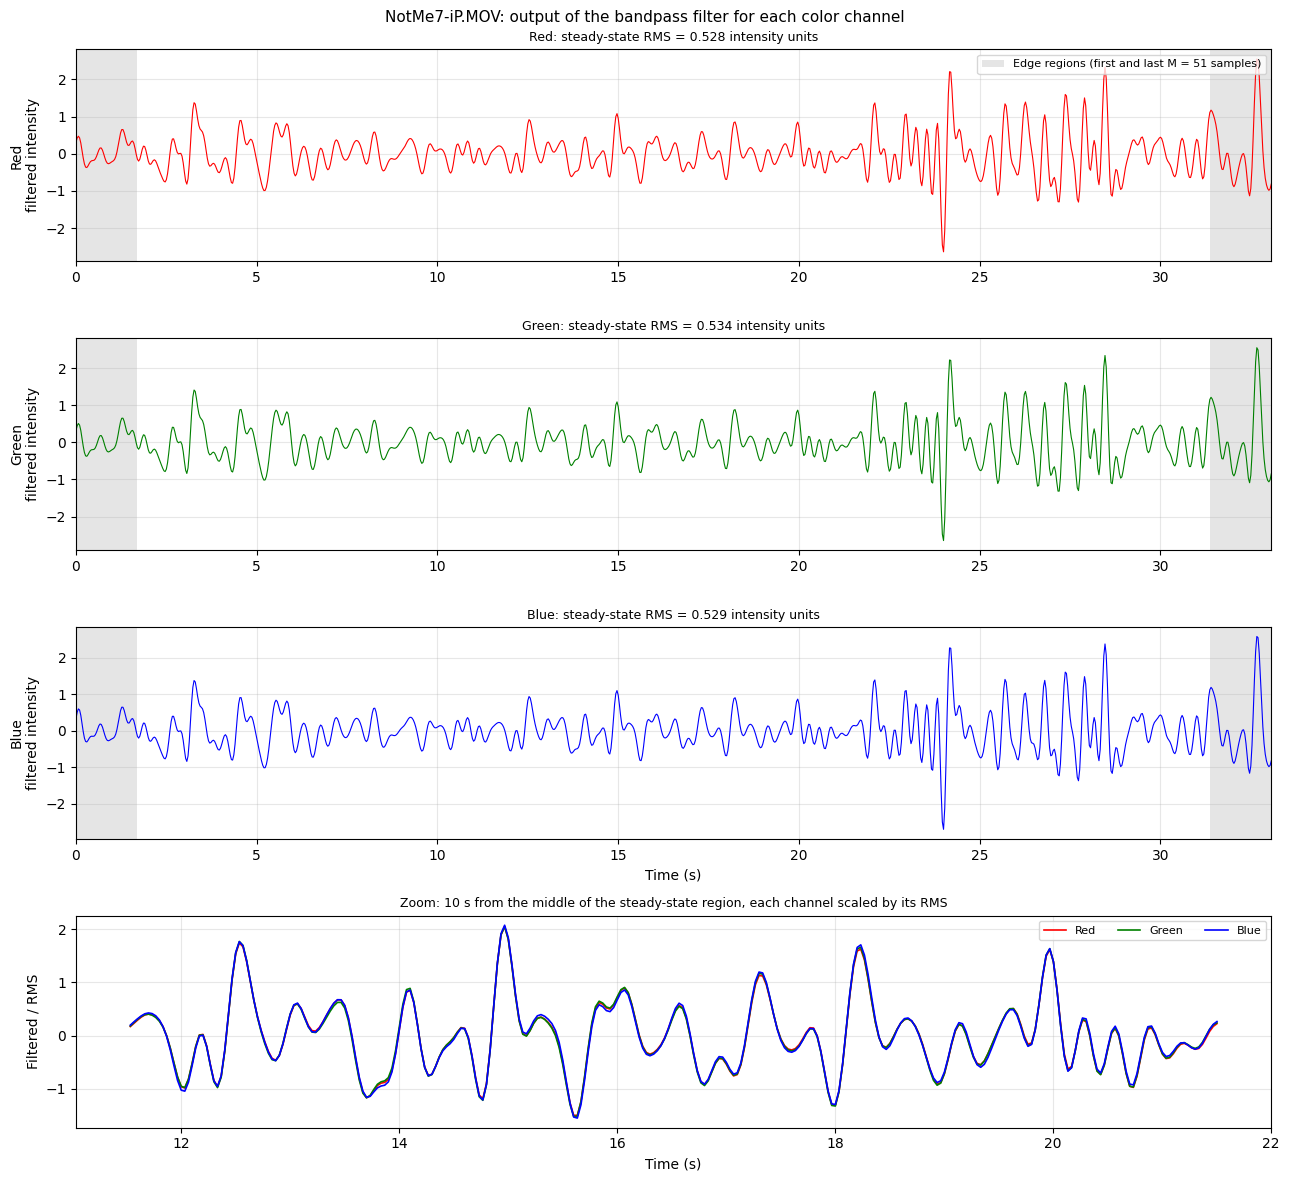

NotMe7-iP.MOV: steady state 1.70 s to 31.37 s (29.7 s of the 33.1 s record)
  correlation between channels: R-G +1.00, R-B +0.99, G-B +0.99


In [27]:
y2 = filter_rgb(filt2, t2, rgb2, t_start=3.0)
plot_filtered(y2, "NotMe7-iP.MOV")

## Part 8: Determine an approach to estimating the power spectral density

Same approach as Video 1, Part 8 (Welch, Hann, 10-s segments, 50% overlap, NFFT 8192, steady-state samples only). The printout gives this video's number of samples and segments.

In [28]:
pz2 = hr_psd(y2, filt2)

Welch PSD of the filtered steady-state output: 891 samples (29.7 s, from t = 1.70 s), Hann window, 300 samples/segment (10.0 s), 150 samples overlap (50%), 4 segments
  NFFT = 8192 (PSD every 0.0037 Hz = 0.22 bpm), resolution ≈ 0.144 Hz = 8.6 bpm (-3 dB), one-sided density


## Part 9: Plot the Power Spectral Density for each of the color channels

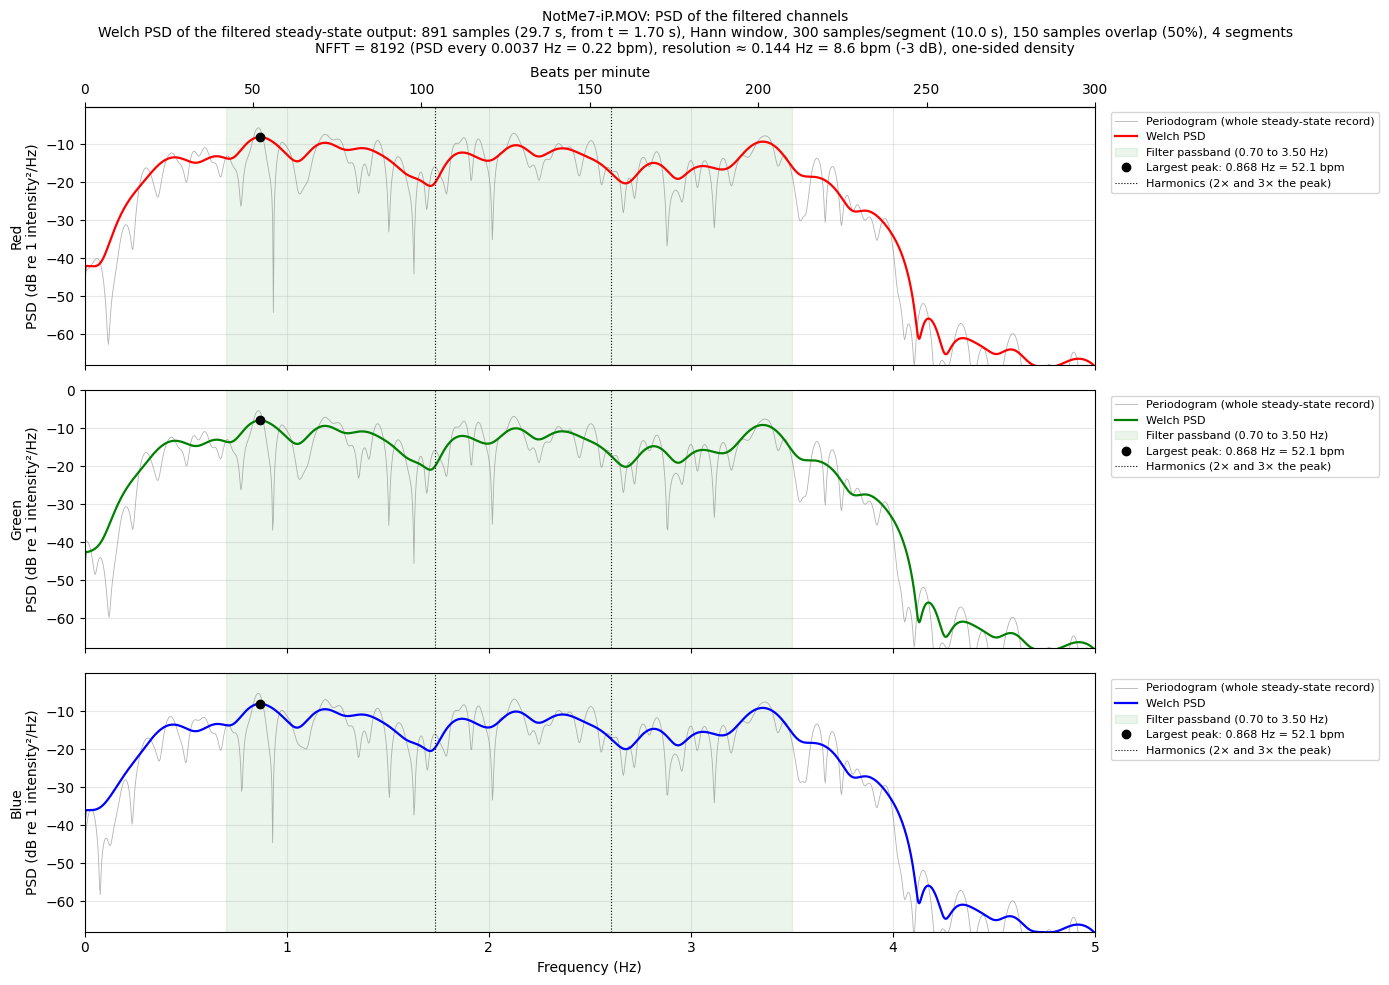

In [29]:
plot_hr_psd(pz2, "NotMe7-iP.MOV")

## Part 10: Estimate the pulse (heart) rate, if present

Same method as Video 1 (see Video 1, Part 10).

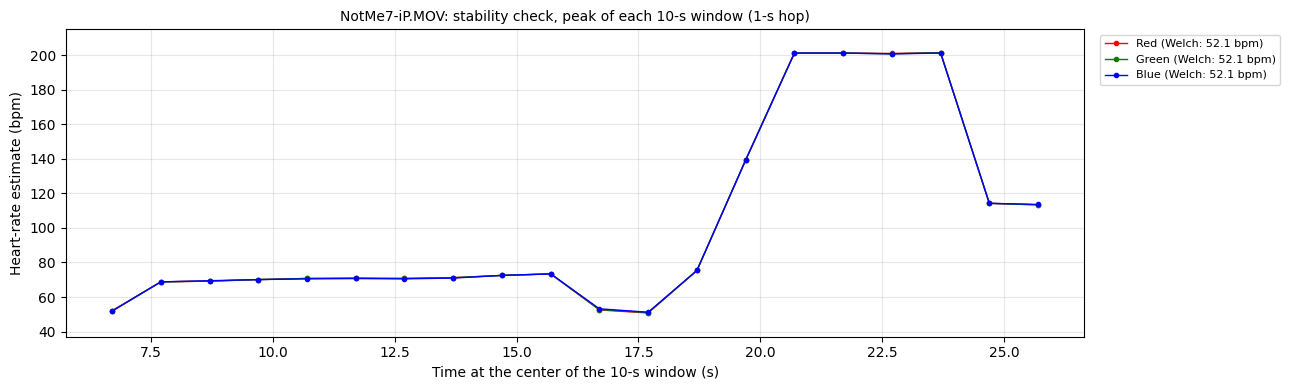

#### NotMe7-iP.MOV: heart-rate estimate

| Channel | Welch peak (bpm) | Peak fraction (need ≥ 0.5; noise ≈ 0.14) | 10-s median (bpm) | 10-s IQR (need ≤ 10 bpm) | Pulse? |
|---|---|---|---|---|---|
| Red | 52.1 | 0.21 | 71.8 | 50.6 | no |
| Green | 52.1 | 0.21 | 71.8 | 50.6 | no |
| Blue | 52.1 | 0.21 | 71.7 | 50.6 | no |

**A pulse does not appear to be present:** no channel passed both tests.

In [30]:
hr2 = estimate_pulse(y2, pz2, "NotMe7-iP.MOV")

## Part 11: Which color channels were most helpful for estimating the pulse rate?

Same method as Video 1 (see Video 1, Part 11).

In [31]:
channel_report(hr2, y2, rgb2, "NotMe7-iP.MOV")

#### NotMe7-iP.MOV: how useful each channel was

| Rank | Channel | Mean intensity | Pulse RMS | Pulse / mean | Peak fraction | 10-s IQR (bpm) | Correlation with red | Passed? |
|---|---|---|---|---|---|---|---|---|
| 1 | Red | 198.8 | 0.528 | 0.27% | 0.21 | 50.6 | +1.00 | no |
| 2 | Green | 197.0 | 0.534 | 0.27% | 0.21 | 50.6 | +1.00 | no |
| 3 | Blue | 197.6 | 0.529 | 0.27% | 0.21 | 50.6 | +0.99 | no |

# Video 3: My finger (`IMG_1133.MOV`)

### Recording procedure

I recorded with an iPhone 16 Pro Max, matching the format of the provided videos (HDR, 1080p at 30 fps):

1. **Camera settings.** Settings → Camera → Formats → **High Efficiency**, and Settings → Camera → Record Video → **1080p at 30 fps** with **HDR Video** on. This records 10-bit HEVC, like the provided videos.
2. **Transfer setting.** Settings → Apps → Photos → Transfer to Mac or PC → **Keep Originals**, so the video is not converted to H.264 when copied to the computer.
3. **Light.** In the Camera app's **Video** mode, I set the flash to **On**, so it stays lit as a torch.
4. **Position.** I sat with my forearm and hand resting on a table and held the phone steady.
5. **Finger.** I rested the pad of my index fingertip lightly over the rear camera lenses **and** the flash. Pressing hard squeezes blood out of the fingertip and weakens the pulse.
6. **Recording.** About 62 seconds, holding still.
7. **Reference.** My watch read **64 bpm** during the recording (`MY_REFERENCE_BPM` above).

My first attempt (`IMG_1130.MOV`) was recorded in the standard 8-bit H.264 format. In that format the green channel came out as exactly 0 and blue as almost 0 (see Part 1), so I re-recorded in HDR.

## Part 1: Plot the average intensity of the red, blue, and green channels versus time

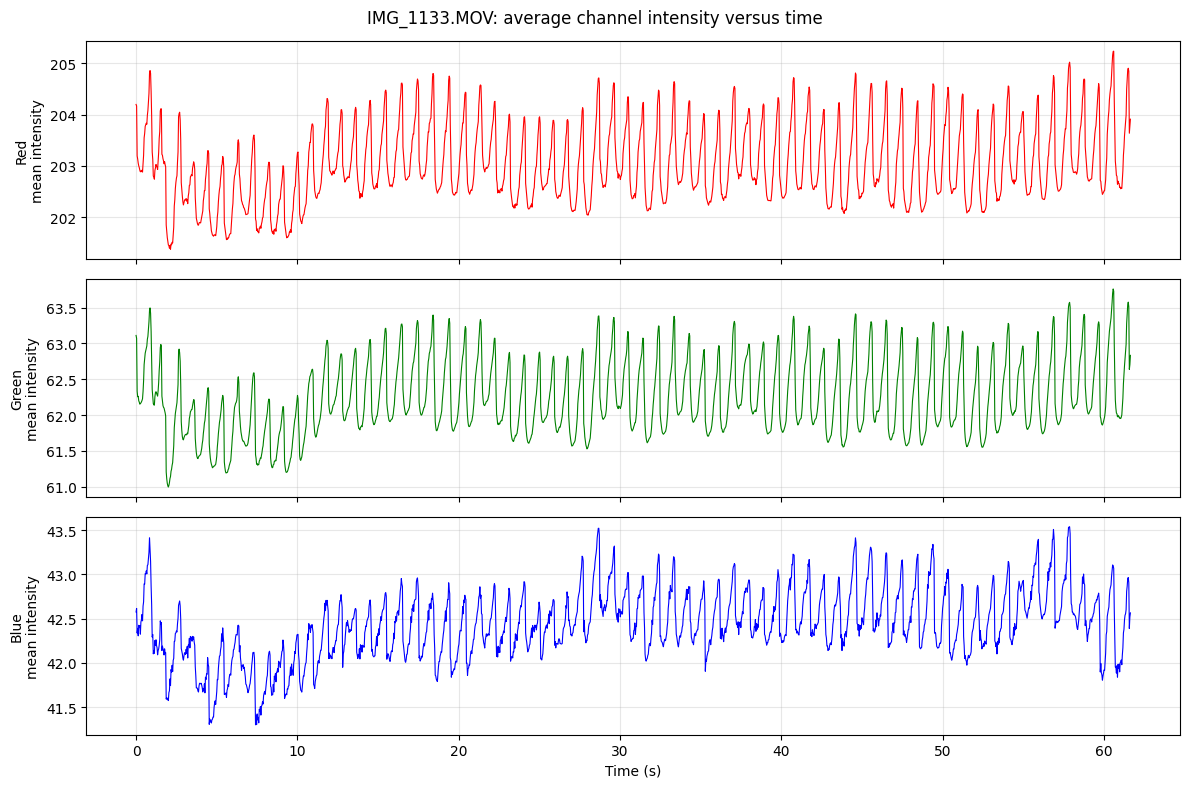

In [32]:
t3, rgb3, fs3 = average_rgb("IMG_1133.MOV")
plot_rgb(t3, rgb3, "IMG_1133.MOV: average channel intensity versus time")

## Part 2: Design a filter to isolate the pulsatile frequency of interest

  Red  : drift sinks into the floor at 0.28 Hz, strongest drift 18.2 dB above the floor
  Green: drift sinks into the floor at 0.28 Hz, strongest drift 18.3 dB above the floor
  Blue : drift sinks into the floor at 0.29 Hz, strongest drift 25.2 dB above the floor
  stopband 0 to 0.29 Hz | passband 0.70 to 3.50 Hz | stopband above 3.91 Hz | attenuation 45.2 dB


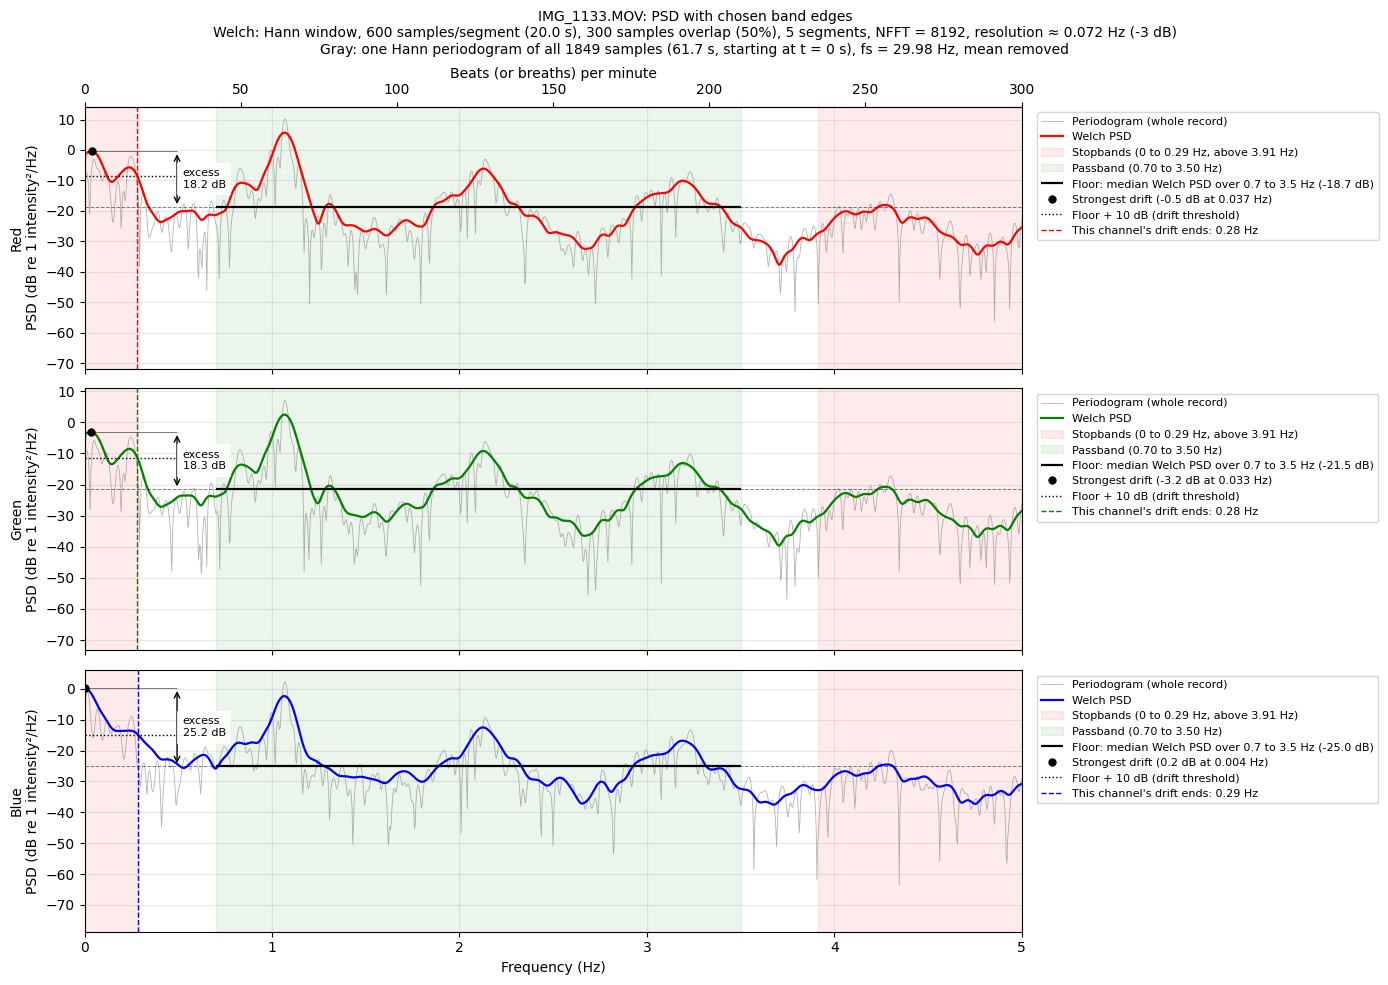

In [33]:
psd3, cut3 = psd_with_cutoffs(t3, rgb3, fs3, "IMG_1133.MOV: PSD with chosen band edges")

In [34]:
filt3 = design_kaiser(cut3, fs3)
design_table([("IMG_1133.MOV", cut3, filt3)], show_common=False)

#### Filter for each video

| Band or value | How it is chosen | IMG_1133.MOV |
|---|---|---|
| Channels that set the edges | One filter is used for all three channels, so the worst of these channels decides | Red, Green, Blue |
| **Lower stopband** | From 0 Hz up to where the drift sinks below the floor + 10 dB (the floor is the median Welch PSD over the passband) | 0 to 0.29 Hz (17 bpm) |
| **Transition band 1** | From the lower stopband edge to the lower passband edge | 0.29 to 0.70 Hz (width 0.41 Hz) |
| Lower cutoff (−6 dB) | Midpoint of transition band 1 | 0.49 Hz (30 bpm) |
| **Passband** | Fixed: the range of heart rates the filter is meant to detect | 0.70 Hz (42 bpm) to 3.50 Hz (210 bpm) |
| **Transition band 2** | Same width as transition band 1 (the Kaiser window method uses one transition width) | 3.50 to 3.91 Hz (width 0.41 Hz) |
| Upper cutoff (−6 dB) | Midpoint of transition band 2 | 3.71 Hz (222 bpm) |
| **Upper stopband** | From the upper stopband edge to half the frame rate ($f_s/2$) | 3.91 to 14.99 Hz |
| Required stopband attenuation | Strongest drift above the floor + 20 dB margin | 45.2 dB |
| Achieved stopband attenuation | Measured from the designed filter's frequency response | 45.3 dB |
| Passband gain | Measured: lowest to highest gain between the passband edges | -0.037 to +0.062 dB |
| Kaiser β | From `kaiserord`: larger β gives more stopband attenuation (and needs more taps for the same transition width) | 4.002 |
| Length N | From `kaiserord`, made odd: longer for more attenuation or a narrower transition | 189 taps (6.31 s) |
| Edge region at each end | Half-length M = (N − 1)/2 samples (Part 4) | 94 samples (3.14 s) |
| Sampling rate $f_s$ | Frame rate of the video | 29.98 Hz |

## Part 3: Plot the impulse response of your filter

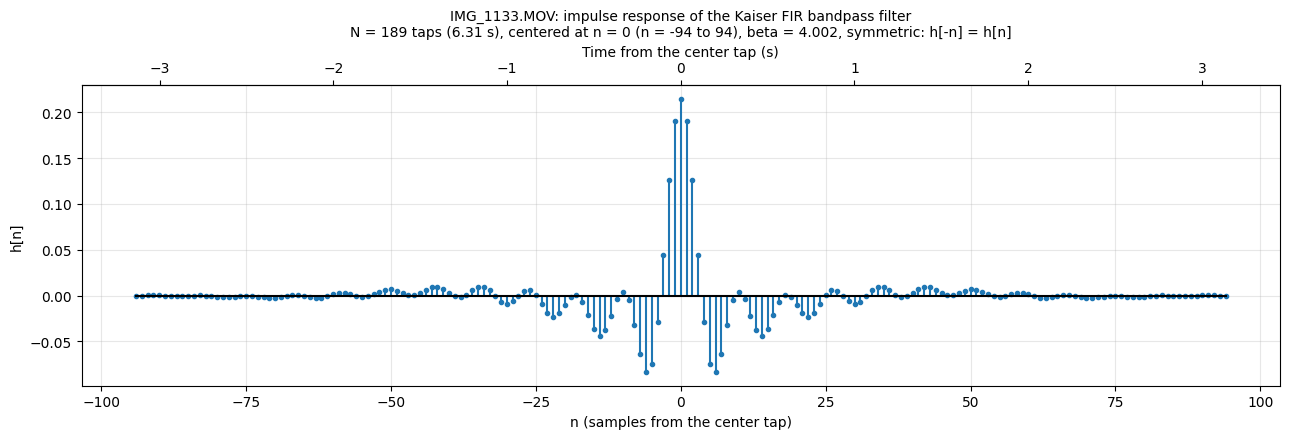

In [35]:
plot_impulse(filt3, "IMG_1133.MOV")

## Part 4: How long do you estimate it would take for the edge effects to become negligible for your filter?

IMG_1133.MOV
  Exact: the edge regions are the first and last M = 94 samples = 3.14 s.
  Worst case (a): less than 1% of sum|h| is missing once the output is 2.14 s from an end.
  Measured (b), Red  : within 1% of the steady-state RMS from 2.67 s to 59.25 s (2.67 s from the start, 2.44 s from the end)
  Measured (b), Green: within 1% of the steady-state RMS from 2.67 s to 59.28 s (2.67 s from the start, 2.40 s from the end)
  Measured (b), Blue : within 1% of the steady-state RMS from 2.57 s to 59.35 s (2.57 s from the start, 2.34 s from the end)


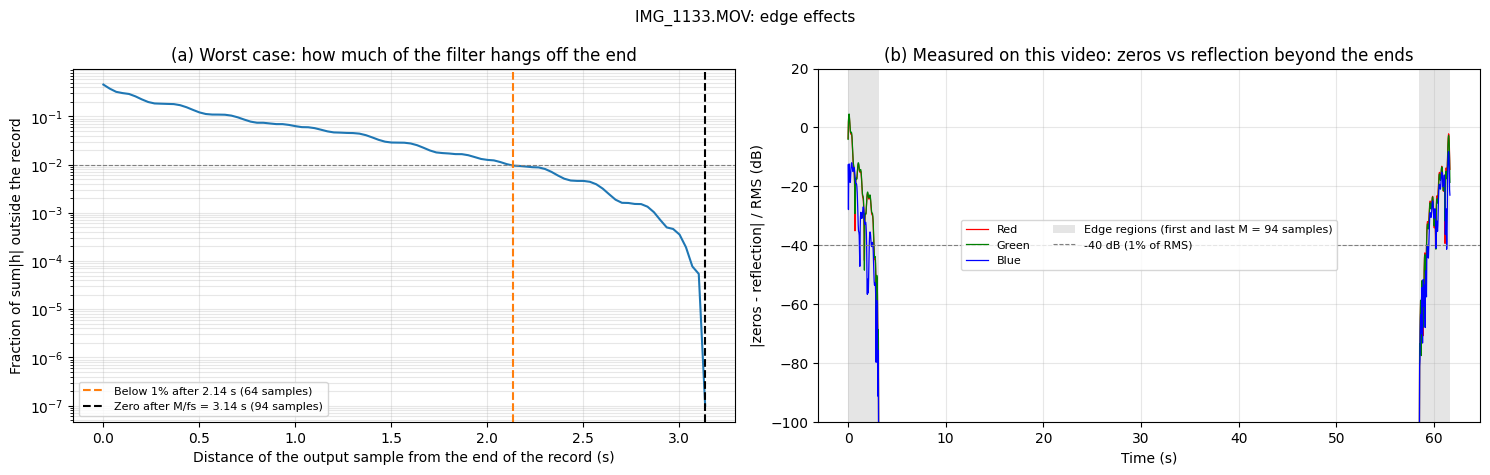

In [36]:
edge_effects(filt3, t3, rgb3, "IMG_1133.MOV")

## Part 5: Plot the magnitude response of your filter

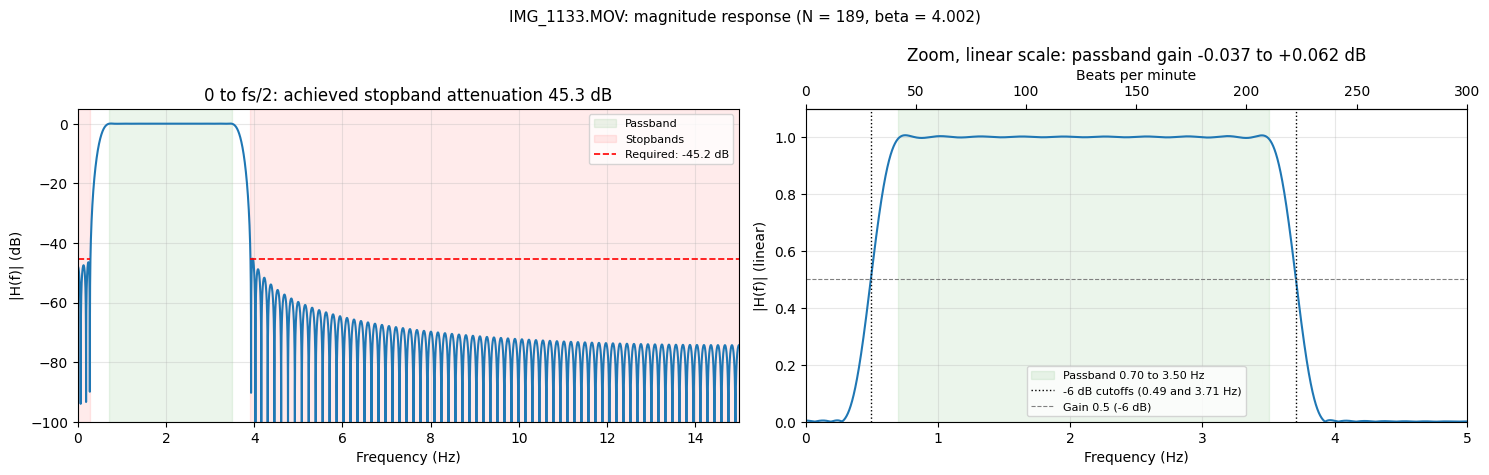

In [37]:
plot_magnitude(filt3, "IMG_1133.MOV")

## Part 6: Plot the phase response of your filter

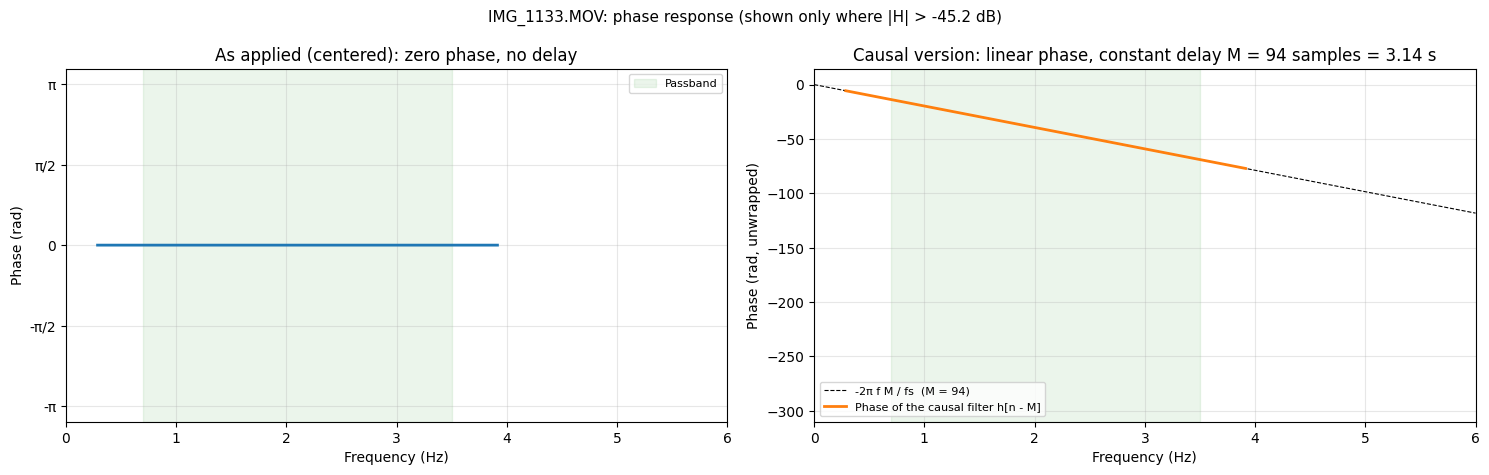

In [38]:
plot_phase(filt3, "IMG_1133.MOV")

## Part 7: Plot the output of your filter for each of the color channels

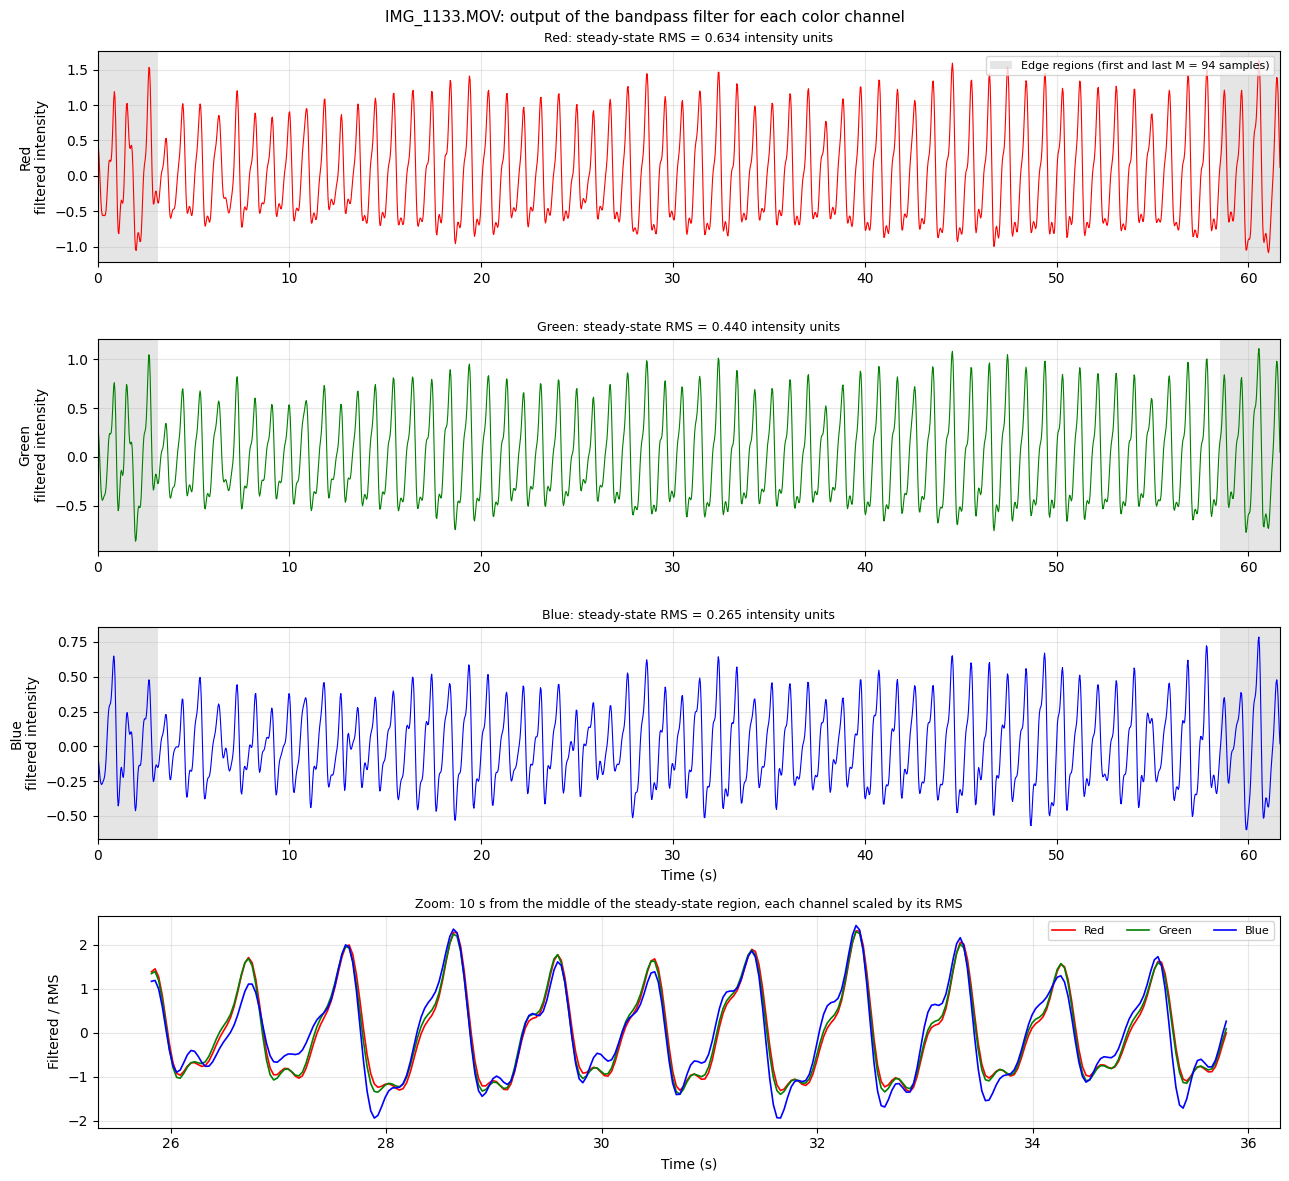

IMG_1133.MOV: steady state 3.14 s to 58.51 s (55.4 s of the 61.7 s record)
  correlation between channels: R-G +0.99, R-B +0.94, G-B +0.96


In [39]:
y3 = filter_rgb(filt3, t3, rgb3)
plot_filtered(y3, "IMG_1133.MOV")

## Part 8: Determine an approach to estimating the power spectral density

Same approach as Video 1, Part 8 (Welch, Hann, 10-s segments, 50% overlap, NFFT 8192, steady-state samples only). The printout gives this video's number of samples and segments.

In [40]:
pz3 = hr_psd(y3, filt3)

Welch PSD of the filtered steady-state output: 1661 samples (55.4 s, from t = 3.14 s), Hann window, 300 samples/segment (10.0 s), 150 samples overlap (50%), 10 segments
  NFFT = 8192 (PSD every 0.0037 Hz = 0.22 bpm), resolution ≈ 0.144 Hz = 8.6 bpm (-3 dB), one-sided density


## Part 9: Plot the Power Spectral Density for each of the color channels

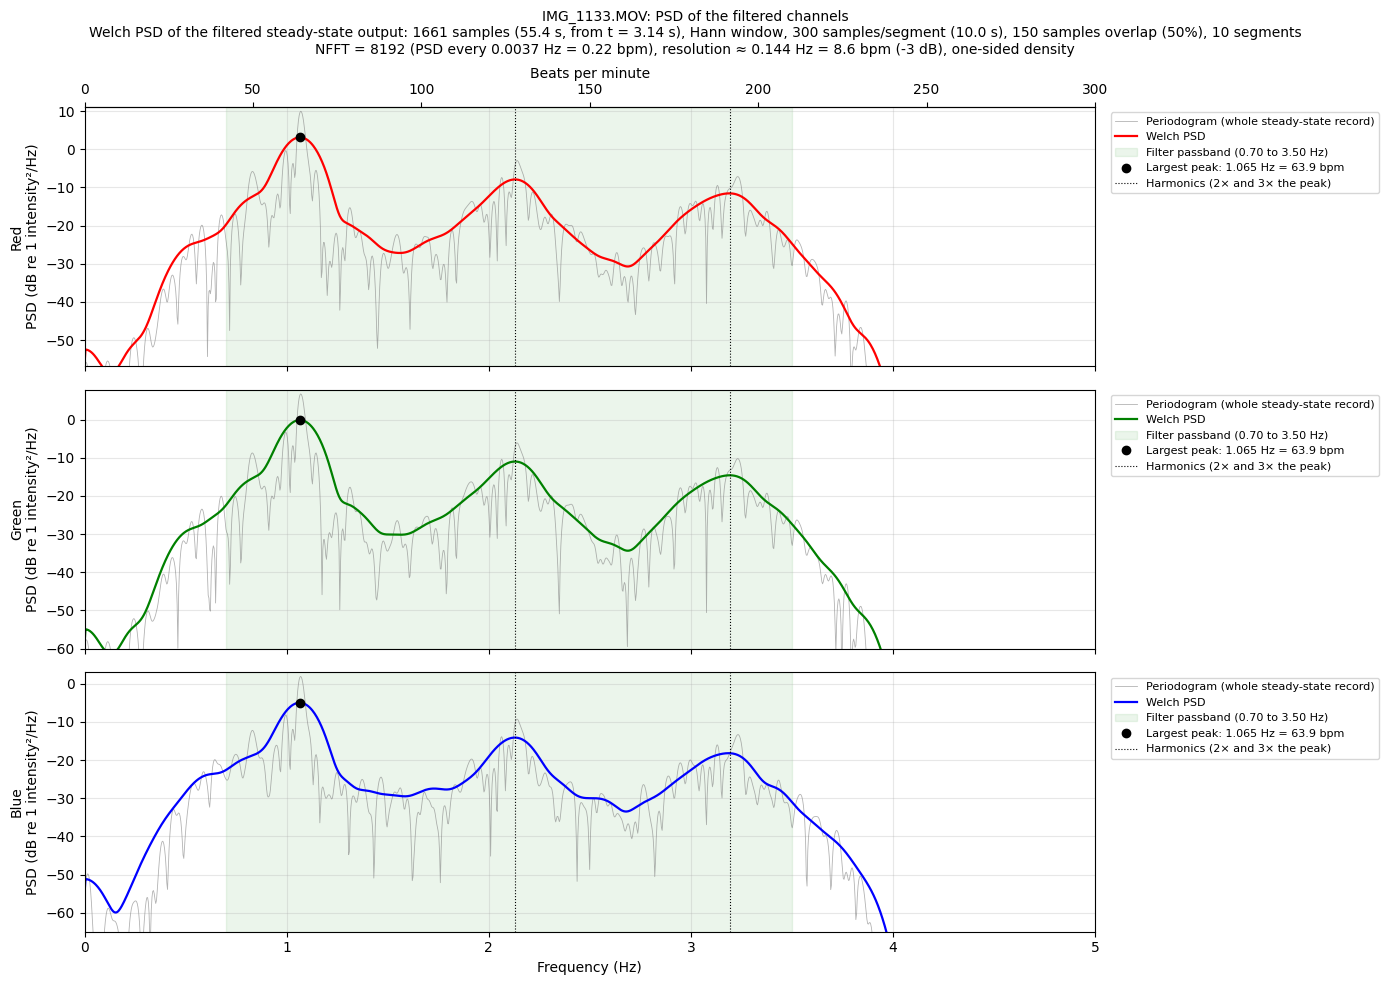

In [41]:
plot_hr_psd(pz3, "IMG_1133.MOV")

## Part 10: Estimate the pulse (heart) rate, if present

Same method as Video 1 (see Video 1, Part 10).

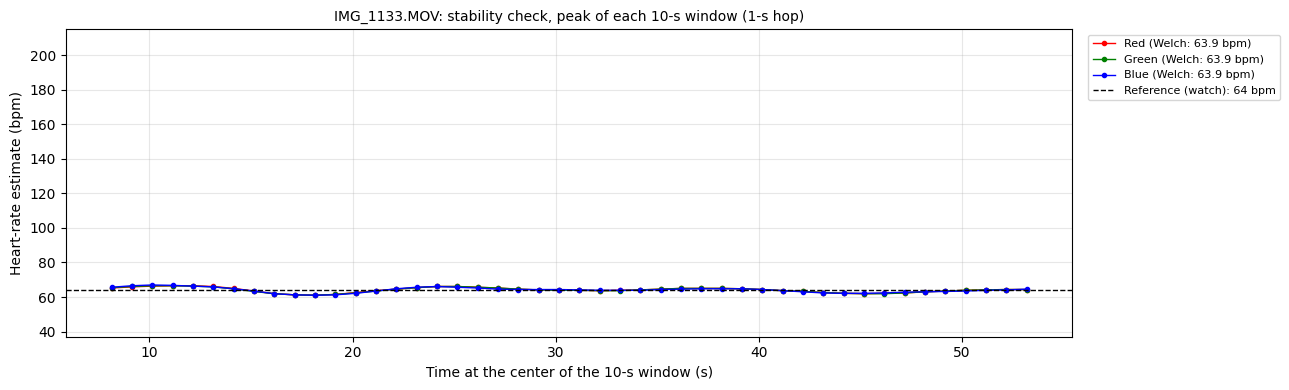

#### IMG_1133.MOV: heart-rate estimate

| Channel | Welch peak (bpm) | Peak fraction (need ≥ 0.5; noise ≈ 0.14) | 10-s median (bpm) | 10-s IQR (need ≤ 10 bpm) | Pulse? |
|---|---|---|---|---|---|
| Red | 63.9 | 0.83 | 64.1 | 1.7 | yes |
| Green | 63.9 | 0.83 | 64.1 | 1.8 | yes |
| Blue | 63.9 | 0.77 | 64.2 | 1.7 | yes |

**Pulse present. Estimated heart rate: 63.9 bpm (1.065 Hz)**, from the red channel (largest peak fraction among the channels that passed). Reference: 64 bpm (difference -0.1 bpm).

In [42]:
hr3 = estimate_pulse(y3, pz3, "IMG_1133.MOV", reference_bpm=64)

## Part 11: Which color channels were most helpful for estimating the pulse rate?

Same method as Video 1 (see Video 1, Part 11).

In [43]:
channel_report(hr3, y3, rgb3, "IMG_1133.MOV")

#### IMG_1133.MOV: how useful each channel was

| Rank | Channel | Mean intensity | Pulse RMS | Pulse / mean | Peak fraction | 10-s IQR (bpm) | Correlation with red | Passed? |
|---|---|---|---|---|---|---|---|---|
| 1 | Red | 203.0 | 0.634 | 0.31% | 0.83 | 1.7 | +1.00 | yes |
| 2 | Green | 62.2 | 0.440 | 0.71% | 0.83 | 1.8 | +0.99 | yes |
| 3 | Blue | 42.4 | 0.265 | 0.62% | 0.77 | 1.7 | +0.94 | yes |

## Part 12: What, if anything, did you learn from this homework?

### Core ideas covered in this assignment

- **Photoplethysmography (PPG).** Light through a fingertip dims slightly with each heartbeat because blood absorbs light, so a phone camera and flash can measure the pulse.
- **The decoder matters.** Converting 10-bit HDR video to 8-bit RGB depends on the software, so channel levels (and how useful a dim channel is) can differ between computers, even though the timing of the beats does not.
- **Letting the data set the filter specs.** The raw PSD showed where the drift ends and how strong it is, which set the lower stopband edge and the attenuation for each video. The passband stayed fixed, because fitting it to where the pulse happens to be would assume the answer.
- **Kaiser window design.** $\beta$ sets the attenuation and `kaiserord` gives the length directly, which beat the fixed windows (Hann, Hamming, Blackman) on length. Parks-McClellan was slightly shorter but harder to use reliably.
- **Edge effects cost data.** A longer filter means more discarded samples at each end. One dim, drifting channel (blue in `Me7-iP.MOV`) nearly tripled the filter length until it was left out of the design decision.
- **Which channel helps depends on physics and on the recording.** Blood absorbs green strongly, so green has a large relative pulse; red is brightest; blue was too dim in one video and fine in another. Channels that move identically (as in `NotMe7-iP.MOV`) point to the camera or light, not to blood.
- **Design choices should be stated.** Thresholds such as 10 dB, 20 dB, 0.5, and 10 bpm are choices, not measurements, and changing them changes the results.

## Part 13: What new questions, if any, do you have?

I have no questions at this time.